# Prédire les short squeezes sur les perpétuels crypto

**Question** : peut-on prédire un short squeeze 24 heures à l'avance à partir du positionnement des traders sur les perpétuels Binance (funding, open interest, ratios long/short, ratio taker) ?

- **H1, shorts informés** : une accumulation de shorts annonce une baisse, et le positionnement ne prédit pas de squeeze.
- **H2, shorts fragiles** : des shorts accumulés avec du levier rendent le marché vulnérable à un rachat forcé.

Les données sont horaires, du 2023-01-01 au 2026-09-30, sur les 10 perpétuels USDT qui avaient le plus gros open interest en décembre 2022 (règle de choix dans le README). Les étapes 1 à 3 décrivent en détail les trois plus grosses cryptos (BTC, ETH et SOL) ; l'étape 4 utilise les 10.

**Démarche.** Les consignes de l'ENSAE ne demandent pas de modèle : on répond à la question par l'analyse descriptive. On cherche si le positionnement change de façon visible **avant** les squeezes, et si ces signaux tiennent pour toutes les cryptos, toutes les périodes et sur une autre plateforme. Un modèle de prévision serait la suite naturelle du projet (voir la conclusion).

In [1]:
from src import descriptif
from src.config import SYMBOLS_DESCRIPTIF
from src.panel_binance import rapport_qualite

panel = descriptif.charger_panel(symboles=SYMBOLS_DESCRIPTIF)
panel.groupby("symbol").size()

symbol
BTCUSDT    32856
ETHUSDT    32856
SOLUSDT    32856
dtype: int64

## 1. Données et univers

Avant de définir la cible, on vérifie deux choses : les données sont-elles fiables, et les trois cryptos sont-elles comparables ?

### Valeurs manquantes

Part des heures manquantes (en %) pour les colonnes qui ont au moins un trou.

In [2]:
qualite = rapport_qualite(panel)
qualite.loc[:, qualite.sum() > 0].T

symbol,BTCUSDT,ETHUSDT,SOLUSDT
basis,0.15,0.15,0.15
oi,0.03,0.03,0.03
oi_usd,0.03,0.03,0.03
ls_top_comptes,0.03,0.03,0.03
ls_top_positions,0.03,0.03,0.03
ls_global,0.03,0.03,0.03
taker_ratio,0.03,0.03,0.03


Les données sont presque complètes : sur 32 856 heures par crypto, aucune variable ne manque plus de 0,15 % du temps. Les trous ont trois origines, toutes chez Binance :
- **la basis** (indice de prime) manque sur des journées entières : le 24 février 2023 pour BTC, le 9 avril 2023 pour ETH et SOL, et le 29 juin 2026 pour les trois ;
- **les relevés à 5 minutes** (open interest et ratios) manquent pendant 9 heures le 16 février 2024, sur les trois cryptos à la fois ;
- une heure de spot (24 mars 2023) et deux heures du ratio des gros traders en comptes (22 juillet 2025).

Ces trous sont trop courts pour biaiser l'analyse, et on ne les comble pas. Aucune des variables de la cible (prix, open interest, volumes) ne manque plus de 9 heures.

### Cohérence du ratio taker

La condition C3 de la cible utilise le ratio taker (achats agressifs / ventes agressives). Binance le donne de deux façons :
- **les relevés à 5 minutes** (`taker_ratio` du panel, moyenne des 12 relevés de l'heure) ;
- **les bougies horaires** : `taker_buy_volume / (volume − taker_buy_volume)`.

On compare les deux, heure par heure.

In [3]:
descriptif.comparer_taker(panel).round(3)

,Médiane bougies,Médiane relevés,Médiane relevés / bougies,Corrélation des log,Même côté de 1 (%)
BTCUSDT,0.988,1.094,1.101,0.705,70.222
ETHUSDT,0.984,1.077,1.088,0.688,70.435
SOLUSDT,0.977,1.046,1.064,0.732,73.938


Les deux mesures vont dans le même sens (corrélation des logarithmes autour de 0,7), mais les relevés sont **6 à 10 % plus élevés** : leur médiane dépasse 1, celle des bougies est en dessous. L'écart vient du calcul : une moyenne de douze ratios est plus grande que le ratio des volumes de l'heure, car un ratio fluctue de façon asymétrique (il ne descend pas sous 0 mais peut monter très haut).

Pour C3, dont le seuil est justement 1, ce choix compte : les deux mesures ne sont du même côté de 1 que 70 à 74 % des heures. Avec la moyenne des relevés, C3 serait vraie plus souvent sans que les acheteurs dominent vraiment. **La cible utilise donc le ratio des bougies**, qui rapporte les volumes réellement échangés pendant l'heure.

### Les trois cryptos

In [4]:
descriptif.tableau_cryptos(panel).round(2)

,Volume quotidien moyen (Md USDT),Open interest moyen (Md USDT),Volatilité annualisée (%),Rendement total (%),Funding moyen annualisé (%),Heures à funding négatif (%),Volume perpétuel / volume spot
BTCUSDT,14.62,5.91,46.08,405.70,7.24,13.56,6.90
ETHUSDT,9.80,3.67,61.14,124.87,7.37,13.90,8.67
SOLUSDT,2.63,0.83,86.31,1082.98,3.86,30.41,5.49


Les trois cryptos ne sont pas comparables en niveau :
- **taille** : BTC échange 14,6 milliards d'USDT par jour sur le perpétuel, SOL cinq fois moins ;
- **volatilité** : SOL est presque deux fois plus volatile que BTC (86 % contre 46 % par an) ;
- **période** : très haussière, de +125 % (ETH) à +1 083 % (SOL), car elle part du creux de fin 2022 ;
- **funding** : positif en moyenne (environ 7 % par an sur BTC et ETH) : les longs paient presque toujours les shorts. Il n'est négatif que 14 % des heures sur BTC et ETH, contre **30 % sur SOL**. Les shorts dominent donc plus souvent sur SOL, la crypto où H2 prévoit le plus de squeezes.
- **levier** : le perpétuel échange 5 à 9 fois le volume du spot (dernière colonne) : l'essentiel des échanges se fait avec levier. C'est ce qui donne du sens à la question : un rachat forcé de shorts sur le perpétuel peut déplacer le prix.

Conséquence : la cible et les variables doivent être relatives à chaque crypto (seuil en écarts-types dans C1, variation relative de l'open interest dans C2, variables normalisées par crypto), pas en niveau.

### Distribution des rendements horaires

In [5]:
descriptif.queues_rendements(panel).round(4)

,Asymétrie,Kurtosis (excès),Au-delà de 4 σ (%)
BTCUSDT,-0.1551,13.2913,0.8644
ETHUSDT,-0.3570,18.1172,0.7792
SOLUSDT,0.1843,11.3202,0.6513
Loi normale,0.0000,0.0000,0.0063


Les rendements horaires ont des **queues très épaisses** : la kurtosis en excès va de 11 à 18 (0 pour une loi normale), et 0,65 à 0,86 % des heures dépassent 4 écarts-types, soit 100 à 140 fois plus qu'avec une loi normale. Le QQ-plot de l'étape 3 (à gauche) le montre : les points quittent la droite dès 2 écarts-types.

Deux conséquences pour la cible :
- **un seuil en écarts-types** est nécessaire, car une même hausse n'a pas le même sens partout. Sur la période, 3·σ·√24 vaut environ 7 % pour BTC, 10 % pour ETH et 14 % pour SOL (volatilité annualisée / √365 × 3). Le plancher de 5 % ne joue donc que dans les périodes calmes ;
- **3 écarts-types ne sont pas un événement à 0,1 %** comme pour une loi normale : les fortes hausses sont plus fréquentes que ne le suggère σ. C'est C2 et C3 qui rendent la cible rare, pas seulement C1.

### Bilan de l'étape 1

- Les données sont fiables : moins de 0,15 % de valeurs manquantes, toujours sur des trous communs venant de Binance.
- Le ratio taker se mesure avec les bougies, pas avec la moyenne des relevés à 5 minutes, qui le surestime.
- Les cryptos diffèrent en taille et en volatilité, et leurs rendements ont des queues épaisses : la cible et les variables doivent être relatives à chaque crypto.

## 2. Variables de positionnement

On décrit les variables qui serviront à départager H1 et H2 :
- **funding** : taux payé par les longs aux shorts (s'il est positif), ramené à 8 h ;
- **variation de l'open interest sur 24 h** : entrée (hausse) ou sortie (baisse) de positions ;
- **trois ratios long/short (L/S)** : nombre de comptes longs divisé par le nombre de comptes courts, pour tous les comptes ou pour les gros traders (les 20 % de comptes qui ont le plus de marge chez Binance), et, pour les gros traders, le même rapport pondéré par la taille des positions ;
- **ratio taker** : achats agressifs / ventes agressives de l'heure, calculé avec les bougies (voir l'étape 1) ;
- **basis** : écart entre le prix du perpétuel et l'indice au comptant.

In [6]:
variables = descriptif.positionnement(panel)
descriptif.resume_positionnement(variables).round(3)

Min     1 %  Médiane    99 %     Max
Funding (% par 8 h)         BTCUSDT  -0.015  -0.008    0.006   0.044   0.088
                            ETHUSDT  -0.037  -0.009    0.006   0.046   0.102
                            SOLUSDT  -0.927  -0.040    0.005   0.056   0.119
Variation OI 24 h (%)       BTCUSDT -25.882  -9.696   -0.010   9.255  24.883
                            ETHUSDT -28.755 -10.281    0.010  11.664  42.471
                            SOLUSDT -29.217 -12.718   -0.062  14.487  58.115
L/S tous comptes            BTCUSDT   0.418   0.530    1.361   2.974   4.173
                            ETHUSDT   0.521   0.782    2.149   4.975   6.314
                            SOLUSDT   0.536   0.814    2.409   5.004   6.029
L/S gros traders, comptes   BTCUSDT   0.503   0.632    1.414   3.218   5.148
                            ETHUSDT   0.537   0.795    2.249   6.224   8.587
                            SOLUSDT   0.574   0.857    2.546   5.513   6.481
L/S gros traders, positions BTCUSDT   0.683   0.790    1.379   2.406   2.821
                            ETHUSDT   0.878   1.027    1.778   4.496   6.120
                            SOLUSDT   0.858   0.940    1.763   3.468   3.961
Ratio taker                 BTCUSDT   0.243   0.609    0.988   1.594   2.739
                            ETHUSDT   0.435   0.645    0.984   1.515   3.332
                            SOLUSDT   0.372   0.654    0.977   1.440   2.320
Basis (%)                   BTCUSDT  -0.816  -0.075   -0.041   0.103   0.427
                            ETHUSDT  -0.659  -0.082   -0.040   0.105   0.568
                            SOLUSDT  -2.067  -0.113   -0.041   0.125   1.096

- **Funding** : une grande partie des heures tombe exactement sur 0,01 % par 8 h, le taux par défaut de Binance (voir le tableau suivant). Le reste est surtout un peu en dessous ; au-dessus, il ne dépasse 0,044 à 0,056 % que 1 % du temps. Le minimum, −0,93 % par 8 h sur SOL le 4 janvier 2023, tombe pendant la hausse de SOL de janvier 2023 : les shorts payaient très cher pour rester en position. C'est le cas typique de H2, à retrouver dans la cible à l'étape 3.
- **Ratios L/S en comptes** : presque toujours au-dessus de 1 (médiane 1,4 pour BTC, 2,1 pour ETH, 2,4 pour SOL). En nombre de comptes, les longs dominent. « Beaucoup de shorts » ne peut donc pas vouloir dire un ratio sous 1 : il faut une mesure relative au niveau habituel de chaque crypto.
- **Ratio L/S des gros traders en positions** : plus proche de 1 et jamais sous 0,68.
- **Ratio taker** : centré un peu sous 1 (0,98) et assez symétrique ; 98 % des heures sont entre 0,61 et 1,59.
- **Variation de l'open interest** : dans ±10 à 15 % sur 24 h pour 98 % des heures, avec des chutes de 26 à 29 % (krachs) et une hausse de 58 % sur SOL.
- **Basis** : négative en médiane (−0,04 %), entre −0,11 et +0,13 % pour 98 % des heures.

### Le funding au taux par défaut

Binance verse le taux par défaut quand la prime du perpétuel sur l'indice est faible. Part des heures où le funding est sous, au ou au-dessus de ce taux, par année :

In [7]:
descriptif.position_du_funding(panel).round(1)

En dessous  Au taux par défaut  Au-dessus
symbol  année                                           
BTCUSDT 2023         55.2                38.5        6.3
        2024         38.5                42.1       19.4
        2025         82.8                17.2        0.0
        2026         93.2                 6.8        0.0
ETHUSDT 2023         55.8                37.2        7.0
        2024         38.3                39.6       22.0
        2025         80.6                19.4        0.0
        2026         94.6                 5.4        0.0
SOLUSDT 2023         49.9                41.2        9.0
        2024         40.6                36.7       22.7
        2025         80.5                19.3        0.2
        2026         86.7                13.3        0.0

Deux régimes se succèdent. En 2023-2024, le funding est au taux par défaut environ 40 % des heures et au-dessus 6 à 23 % des heures. En 2025-2026, il est en dessous 80 à 95 % des heures et **presque jamais au-dessus** (0,2 % des heures au plus) : les longs ne paient plus de prime. La même rupture apparaît sur Bybit, ce n'est donc pas une erreur des fichiers Binance. Une valeur au taux par défaut dit seulement que le marché n'est pas tendu ; l'information est dans les écarts à ce taux, et leur sens a changé entre les deux périodes. Pour les variables, on utilisera donc l'écart au taux par défaut plutôt que le niveau.

### Évolution de 2023 à 2026

Moyennes quotidiennes ; les pointillés marquent trois événements de marché.

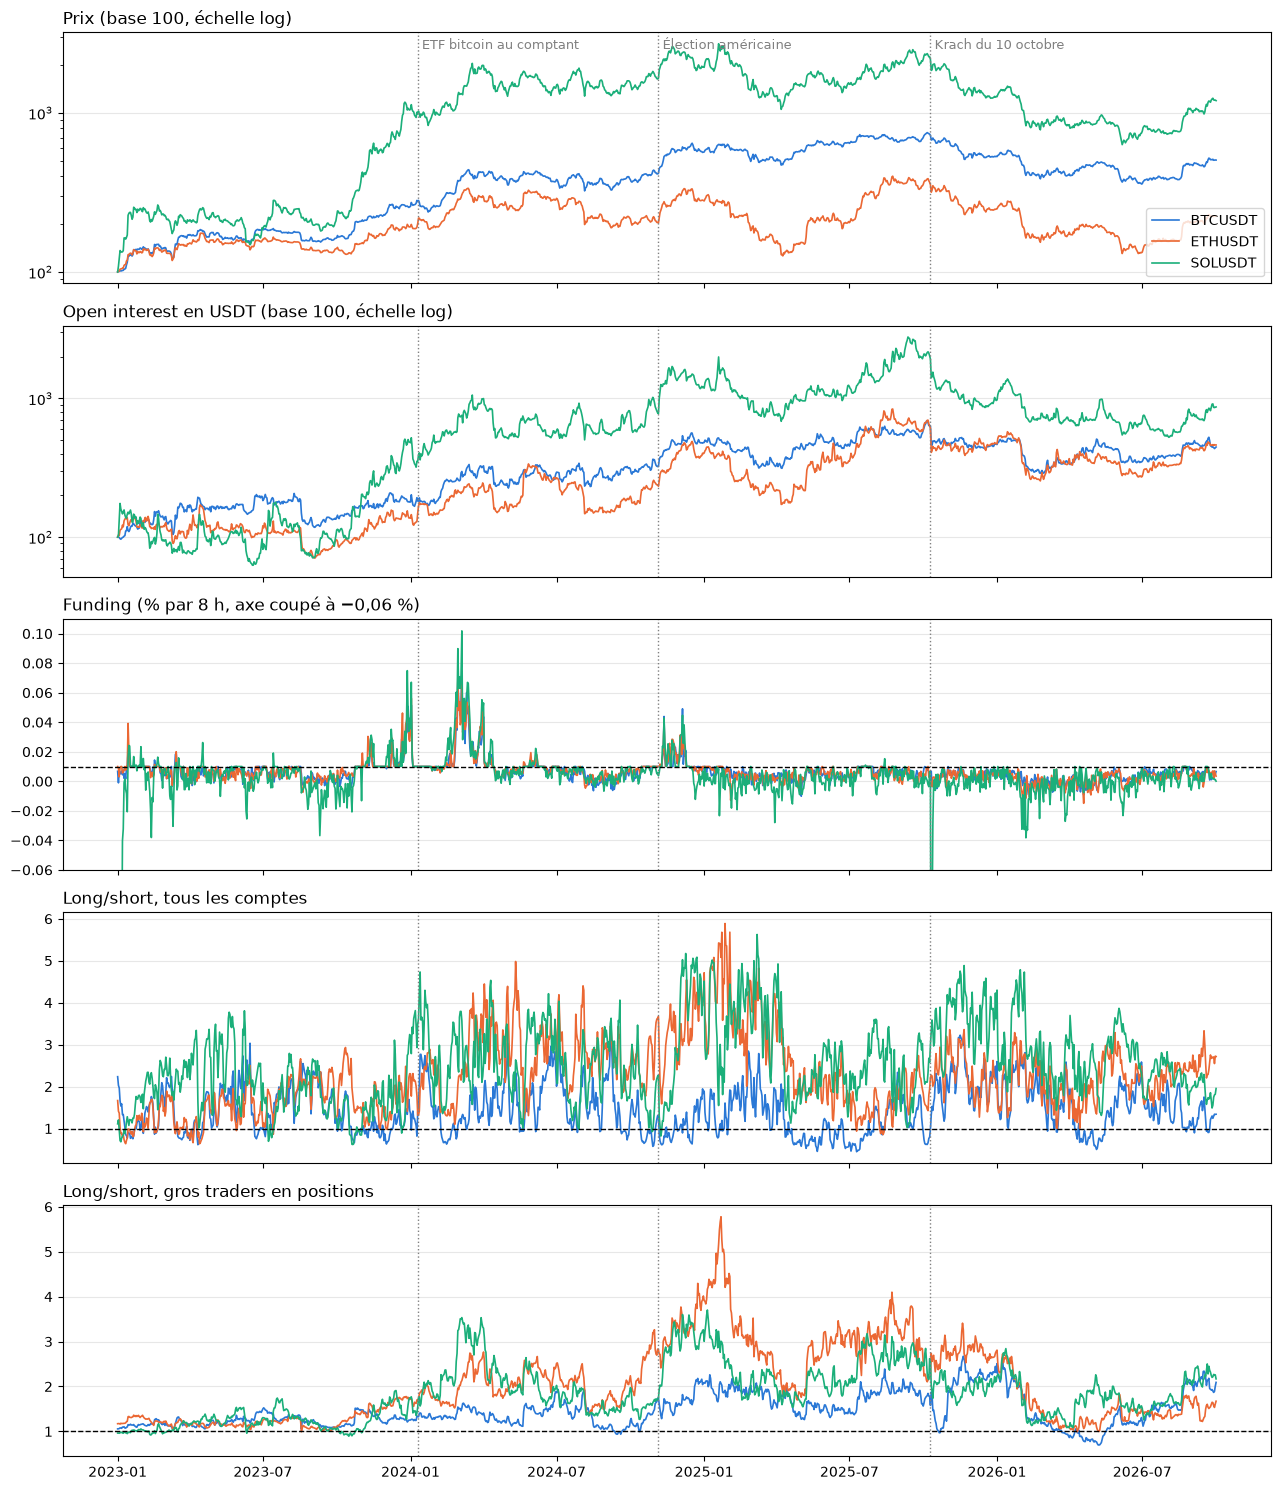

In [8]:
descriptif.graphique_series(panel, variables)

In [9]:
descriptif.medianes_par_an(variables).round(3)

Funding (% par 8 h)  Variation OI 24 h (%)  L/S tous comptes  \
symbol  année                                                                 
BTCUSDT 2023                 0.008                  0.063             1.298   
        2024                 0.010                  0.172             1.353   
        2025                 0.005                 -0.129             1.325   
        2026                 0.003                 -0.148             1.472   
ETHUSDT 2023                 0.008                 -0.063             1.539   
        2024                 0.010                  0.165             2.740   
        2025                 0.005                  0.005             2.260   
        2026                 0.003                 -0.088             2.222   
SOLUSDT 2023                 0.010                 -0.205             1.822   
        2024                 0.010                  0.105             2.666   
        2025                 0.002                 -0.047             2.890   
        2026                 0.000                 -0.133             2.456   

               L/S gros traders, comptes  L/S gros traders, positions  \
symbol  année                                                           
BTCUSDT 2023                       1.246                        1.208   
        2024                       1.438                        1.374   
        2025                       1.457                        1.853   
        2026                       1.570                        1.314   
ETHUSDT 2023                       1.519                        1.209   
        2024                       3.100                        2.114   
        2025                       2.639                        2.905   
        2026                       1.910                        1.407   
SOLUSDT 2023                       1.734                        1.185   
        2024                       2.730                        1.954   
        2025                       3.189                        2.174   
        2026                       2.773                        1.657   

               Ratio taker  Basis (%)  
symbol  année                          
BTCUSDT 2023         0.991     -0.038  
        2024         0.983     -0.025  
        2025         0.979     -0.044  
        2026         1.001     -0.047  
ETHUSDT 2023         0.990     -0.037  
        2024         0.975     -0.026  
        2025         0.979     -0.044  
        2026         0.993     -0.048  
SOLUSDT 2023         0.985     -0.030  
        2024         0.969     -0.026  
        2025         0.971     -0.047  
        2026         0.983     -0.050

- **Phases du marché** : début 2024 (ETF bitcoin) et fin 2024 (élection américaine), les prix et l'open interest montent ensemble et le funding dépasse nettement le taux par défaut : les longs paient cher, le marché est tendu à la hausse. En 2025-2026, le funding passe plus souvent sous le taux par défaut, et devient franchement négatif sur SOL au moment du krach du 10 octobre 2025.
- **Les niveaux dérivent** : la médiane du ratio L/S de tous les comptes sur ETH passe de 1,5 en 2023 à 2,7 en 2024 ; celle du ratio des gros traders en positions sur BTC passe de 1,2 en 2023 à 1,9 en 2025, puis 1,3 en 2026.

Un même niveau n'a donc pas le même sens selon l'année et la crypto. Pour comparer des heures entre elles, il faut donc des mesures relatives, comme des **z-scores glissants par crypto** (écart à la moyenne des 30 derniers jours, divisé par l'écart-type).

### Corrélations entre variables

Corrélations de rang (Spearman), moins sensibles aux valeurs extrêmes que celles de Pearson.

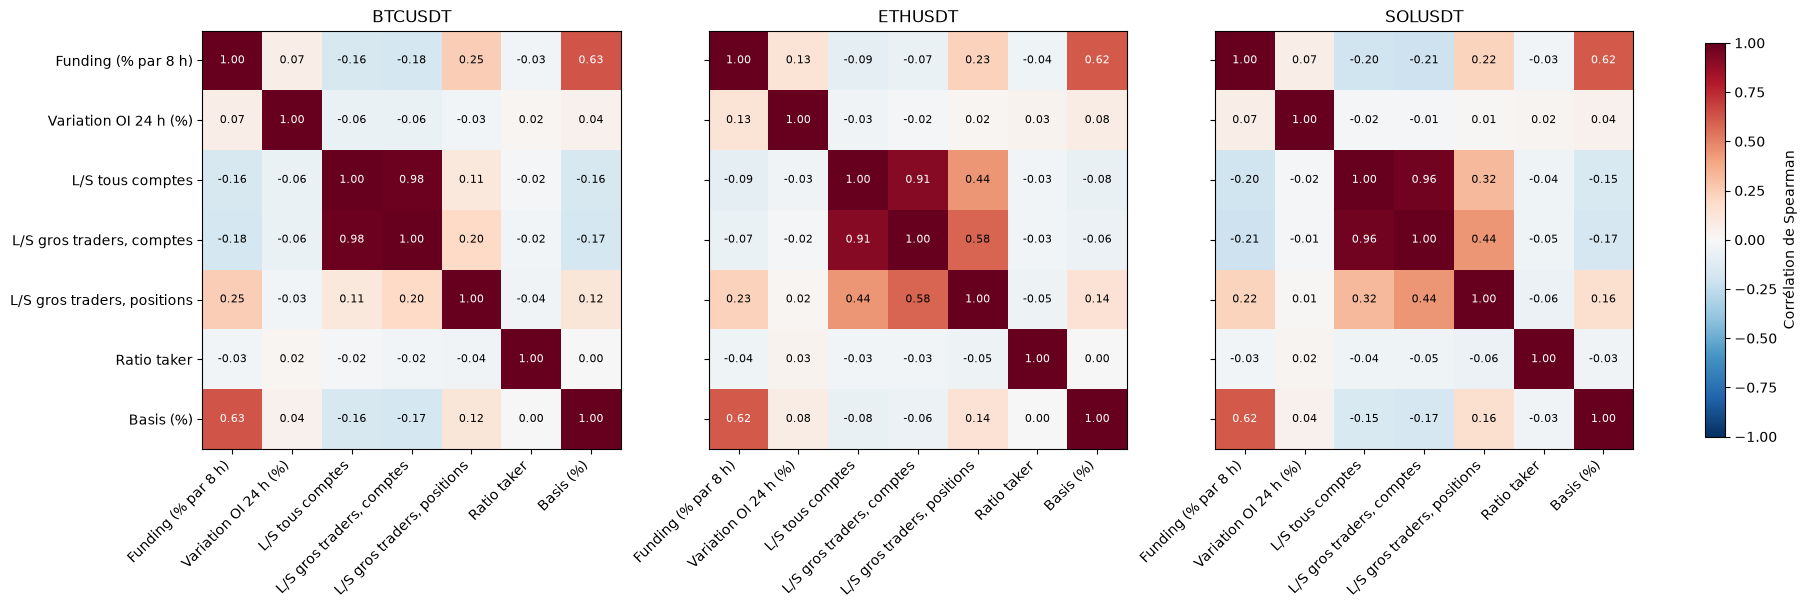

In [10]:
descriptif.graphique_correlations(variables)

- **Les deux ratios en comptes sont presque identiques** (0,91 à 0,98) : ils portent la même information, et les mettre ensemble dans une régression poserait un problème de multicolinéarité : un seul suffit.
- **Le ratio en positions est différent** (0,11 à 0,58 avec les ratios en comptes) : il mesure la taille des paris, pas le nombre de parieurs.
- **Funding et basis** (0,62) : lien en partie mécanique, car Binance calcule le funding à partir de la prime du perpétuel.
- **La variation d'open interest et le ratio taker** ne sont corrélés à rien (moins de 0,15 en valeur absolue) : ils apportent une information à part.

### Positionnement et rendement passé

Le positionnement apporte-t-il une information propre ? Il faut savoir quelle part de lui reflète simplement le prix : corrélation de chaque variable avec le rendement des 7 derniers jours.

In [11]:
descriptif.correlations_rendement_passe(panel, variables).round(2)

,BTCUSDT,ETHUSDT,SOLUSDT
Funding (% par 8 h),0.20,0.33,0.34
Variation OI 24 h (%),0.05,0.08,0.04
L/S tous comptes,-0.69,-0.51,-0.62
"L/S gros traders, comptes",-0.66,-0.47,-0.53
"L/S gros traders, positions",-0.07,-0.01,0.03
Ratio taker,0.05,0.02,0.03
Basis (%),0.20,0.26,0.28


Les ratios en comptes sont **fortement liés au rendement passé** (−0,5 à −0,7) : quand le prix baisse, une plus grande part des comptes est longue, comme si beaucoup de comptes achetaient la baisse. Le ratio des gros traders en positions n'y est pas lié (entre −0,07 et 0,03), et le funding l'est un peu, dans l'autre sens (0,2 à 0,34).

Conséquence pour la question : une bonne part de l'information des ratios en comptes est déjà dans les prix. C'est surtout le ratio en positions qui peut apporter une information que le prix n'a pas.

### Persistance

Autocorrélation de chaque variable avec elle-même 1 heure, 24 heures et 7 jours plus tôt, en moyenne sur les trois cryptos.

In [12]:
descriptif.persistance(variables).round(2)

,1 h,24 h,7 jours
Variable,,,
Funding (% par 8 h),0.97,0.63,0.43
Variation OI 24 h (%),0.97,-0.12,-0.03
L/S tous comptes,1.00,0.87,0.58
"L/S gros traders, comptes",1.00,0.89,0.68
"L/S gros traders, positions",1.00,0.98,0.90
Ratio taker,-0.01,0.01,0.01
Basis (%),0.84,0.73,0.60


- **Les ratios L/S évoluent lentement** : 0,87 à 0,98 à 24 h, et encore 0,58 à 0,90 à 7 jours. Ils décrivent un état du marché plutôt qu'un choc. Un signal extrême reste donc présent plusieurs jours : deux heures proches ne sont donc pas des observations indépendantes.
- **Le funding** est persistant lui aussi (0,63 à 24 h). Son 0,97 à 1 h est en partie mécanique : le taux ne change qu'à chaque paiement, toutes les 8 h.
- **La variation de l'open interest sur 24 h** : le 0,97 à 1 h est mécanique, car deux fenêtres de 24 h décalées d'une heure ont 23 heures en commun. À 24 h, il n'y a plus de persistance (−0,12).
- **Le ratio taker** n'a aucune mémoire, même d'une heure à l'autre (−0,01). Comme variable, il faudra le moyenner sur plusieurs heures.

### Bilan de l'étape 2

- Les niveaux des ratios et du funding changent selon la crypto et l'année : on utilisera des z-scores glissants par crypto, et l'écart du funding au taux par défaut.
- Les deux ratios L/S en comptes sont redondants, et très liés au rendement passé ; le ratio des gros traders en positions apporte une information distincte du prix.
- Les variables lentes (ratios, funding) décrivent un état du marché, les variables rapides (ratio taker, variation d'open interest) des chocs : les deux familles se complètent.

## 3. La cible

Une heure t est positive s'il y a un short squeeze dans les 24 heures qui suivent, c'est-à-dire si les trois conditions sont réunies :
- **C1, forte hausse** : le plus haut des 24 h suivantes dépasse le prix de clôture connu à t d'au moins max(k·σ·√24, plancher), σ étant l'écart-type des rendements horaires des 30 derniers jours ;
- **C2, rachat des shorts** : entre t et ce pic, l'open interest baisse d'au moins δ ;
- **C3, pression acheteuse** : entre t et le pic, les achats agressifs dépassent les ventes agressives (ratio taker > 1).

Pour ce premier calcul, on prend les valeurs de base (constantes de `src/cible.py`) :

| Paramètre | Valeur |
|---|---|
| C1 : k (nombre d'écarts-types) | 3 |
| C1 : plancher de hausse | 5 % |
| C1 : fenêtre de σ | 30 jours |
| C2 : δ (baisse de l'open interest) | 10 % |
| C3 : seuil du ratio taker | 1 |
| Horizon | 24 h |

La sensibilité à ces choix est étudiée à la fin de cette partie. Elle conduit à exprimer δ en écarts-types pour l'étape 4.

La cible est calculée par `src/cible.py` sur le panel complet, car σ a besoin des 30 jours de chauffe, puis on garde la période d'étude. Les dernières heures de la série n'ont pas 24 h de futur : leur cible est inconnue.

Avec une fenêtre de 24 h, un même squeeze rend positives plusieurs heures t de suite. On compte donc aussi des **épisodes** : deux heures positives à moins de 24 h d'écart appartiennent au même épisode, car leurs fenêtres se chevauchent. Chaque épisode est décrit par son heure à la plus forte hausse.

In [13]:
from src.cible import ajouter_cible

panel_complet = descriptif.charger_panel(avec_chauffe=True, symboles=SYMBOLS_DESCRIPTIF)
panel_cible_complet = ajouter_cible(panel_complet)
panel_cible = descriptif.periode_etude(panel_cible_complet)
episodes_cible = descriptif.tableau_episodes(panel_cible)
episodes_cible.round({"hausse_pic_pct": 2, "variation_oi_pct": 2, "ratio_achats_ventes": 2})

,symbol,debut,fin,heures_positives,date_pic,delai_pic_h,hausse_pic_pct,variation_oi_pct,ratio_achats_ventes
0,BTCUSDT,2023-01-13 02:00:00+00:00,2023-01-14 00:00:00+00:00,17,2023-01-14 01:00:00+00:00,23.0,14.55,-10.06,1.08
1,BTCUSDT,2023-01-20 11:00:00+00:00,2023-01-20 20:00:00+00:00,10,2023-01-21 11:00:00+00:00,23.0,11.32,-11.76,1.09
2,BTCUSDT,2023-10-15 14:00:00+00:00,2023-10-16 13:00:00+00:00,18,2023-10-16 14:00:00+00:00,24.0,14.41,-12.39,1.09
3,BTCUSDT,2024-02-27 18:00:00+00:00,2024-02-28 13:00:00+00:00,9,2024-02-28 18:00:00+00:00,24.0,13.20,-10.54,1.04
4,ETHUSDT,2023-01-13 01:00:00+00:00,2023-01-14 00:00:00+00:00,24,2023-01-14 01:00:00+00:00,11.0,17.13,-15.84,1.13
5,ETHUSDT,2023-03-12 05:00:00+00:00,2023-03-12 12:00:00+00:00,8,2023-03-13 01:00:00+00:00,18.0,11.39,-11.64,1.10
6,ETHUSDT,2023-06-16 06:00:00+00:00,2023-06-16 11:00:00+00:00,6,2023-06-17 06:00:00+00:00,21.0,6.32,-10.45,1.10
7,ETHUSDT,2024-02-26 10:00:00+00:00,2024-02-26 14:00:00+00:00,5,2024-02-27 03:00:00+00:00,17.0,8.30,-11.32,1.06
8,SOLUSDT,2023-01-01 08:00:00+00:00,2023-01-02 07:00:00+00:00,24,2023-01-02 08:00:00+00:00,23.0,24.16,-11.68,1.11
9,SOLUSDT,2023-01-08 02:00:00+00:00,2023-01-08 20:00:00+00:00,19,2023-01-09 16:00:00+00:00,21.0,29.37,-12.12,1.08


On trouve **16 épisodes** : 4 pour BTC, 4 pour ETH et 8 pour SOL. Ils regroupent 199 heures positives, soit 12 heures en moyenne par épisode.

### Fréquence

Nombre d'heures positives et d'épisodes, par crypto et par année.

In [14]:
descriptif.frequence_cible(panel_cible, episodes_cible).round(3)

heures  heures_positives  episodes  part_positive_pct
symbol  année                                                       
BTCUSDT 2023     8760                45         3              0.514
        2024     8784                 9         1              0.102
        2025     8760                 0         0              0.000
        2026     6528                 0         0              0.000
        Total   32832                54         4              0.164
ETHUSDT 2023     8760                38         3              0.434
        2024     8784                 5         1              0.057
        2025     8760                 0         0              0.000
        2026     6528                 0         0              0.000
        Total   32832                43         4              0.131
SOLUSDT 2023     8760               101         7              1.153
        2024     8784                 0         0              0.000
        2025     8760                 0         0              0.000
        2026     6528                 1         1              0.015
        Total   32832               102         8              0.311

- **Les squeezes sont très rares** : 0,13 % des heures pour ETH, 0,16 % pour BTC et 0,31 % pour SOL. Ces parts seraient la **base naïve** d'un modèle de prévision : un modèle qui tirerait au hasard aurait cette précision. Avec si peu de positifs, l'accuracy n'a aucun sens : un modèle qui répond toujours « pas de squeeze » aurait raison 99,7 % du temps.
- **Ils se concentrent en 2023** : 13 épisodes sur 16. Il y en a 2 en 2024, aucun en 2025, et un seul en 2026 (SOL, août).
- **Conséquence** : toute comparaison dans le temps repose sur très peu d'épisodes récents.

### Entonnoir C1 → C1 + C2 → C1 + C2 + C3

Parmi les heures qui connaissent une forte hausse (C1), combien s'accompagnent d'une baisse de l'open interest (C2), puis d'une pression acheteuse (C3) ? La deuxième colonne compte les fortes hausses pendant lesquelles l'open interest **monte** : de nouvelles positions s'ouvrent, ce n'est pas un rachat de shorts.

In [15]:
descriptif.entonnoir(panel_cible)

,C1 : forte hausse,C1 et open interest en hausse,C1 + C2 : baisse de l'open interest,C1 + C2 + C3 : short squeeze
symbol,,,,
BTCUSDT,810,437,54,54
ETHUSDT,763,448,49,43
SOLUSDT,781,450,103,102


- **Les fortes hausses sont courantes** (760 à 810 heures par crypto), mais **plus de la moitié** (54 à 59 %) se font avec un open interest en hausse : elles viennent de nouveaux longs, pas d'un rachat de shorts.
- **C2 fait presque tout le tri** : il ne reste que 6 à 13 % des heures C1. C'est elle qui sépare un squeeze d'une simple hausse, et elle correspond bien au mécanisme visé.
- **C3 n'enlève presque rien** (54 → 54 pour BTC, 49 → 43 pour ETH, 103 → 102 pour SOL) : quand les shorts sont rachetés, les achats agressifs dominent presque toujours. C3 confirme le mécanisme mais n'apporte presque pas d'information.

### Simultanéité

Parmi les heures positives d'une crypto (ligne), part des heures où une autre crypto (colonne) est aussi positive.

In [16]:
descriptif.simultaneite(panel_cible).round(1)

symbol,BTCUSDT,ETHUSDT,SOLUSDT,Au moins une autre
symbol,,,,
BTCUSDT,100.0,31.5,31.5,31.5
ETHUSDT,39.5,100.0,74.4,74.4
SOLUSDT,16.7,31.4,100.0,31.4


- **Les squeezes sont souvent communs à plusieurs cryptos** : 31 % des heures positives de BTC et de SOL, et 74 % de celles d'ETH, le sont aussi pour une autre crypto.
- Trois mouvements de marché regroupent 7 des 16 épisodes : le **13-14 janvier 2023** (les trois cryptos), le **rebond de mars 2023** après la crise de SVB et de l'USDC (ETH et SOL), et **fin février 2024** (BTC et ETH).
- Un squeeze est donc souvent un événement de marché plus qu'une affaire propre à une crypto. Les positifs ne sont pas indépendants d'une crypto à l'autre, ce qui réduit encore le nombre d'événements réellement distincts.

### Profil d'un squeeze

Valeurs médianes par crypto : nombre d'heures positives, délai entre t et le pic, hausse au pic, variation de l'open interest et ratio taker entre t et le pic.

In [17]:
descriptif.profil_episodes(episodes_cible).round(2)

,episodes,heures_positives,delai_pic_h,hausse_pic_pct,variation_oi_pct,ratio_achats_ventes
symbol,,,,,,
BTCUSDT,4,13.5,23.5,13.81,-11.15,1.08
ETHUSDT,4,7.0,17.5,9.85,-11.48,1.10
SOLUSDT,8,13.0,21.5,17.89,-11.76,1.07


- **Ampleur** : la hausse médiane va de 10 % (ETH) à 18 % (SOL), en accord avec la volatilité de chaque crypto. Le plus gros épisode est celui de SOL en janvier 2023 (+50 % en 19 heures).
- **Délai** : le pic arrive en médiane 17 à 24 heures après t, souvent au bout de la fenêtre. Les squeezes sont des hausses qui durent, pas des pics d'une heure.
- **L'open interest baisse de 11 à 12 % en médiane**, juste au-delà du seuil de 10 % : beaucoup d'épisodes passent C2 de peu. La cible sera donc sensible au choix de δ (voir ci-dessous).
- **Le ratio taker** n'est que légèrement supérieur à 1 (1,07 à 1,10), ce qui confirme que C3 est peu exigeante.

### Sensibilité aux seuils

Part des heures positives et nombre d'épisodes quand on change un seul seuil de la cible.

In [18]:
descriptif.sensibilite(panel_complet).round(3)

Heures positives (%)                 Épisodes                
                          BTCUSDT ETHUSDT SOLUSDT  BTCUSDT ETHUSDT SOLUSDT
Base                        0.164   0.131   0.311      4.0     4.0     8.0
k = 2,5                     0.168   0.143   0.347      4.0     4.0    11.0
k = 4                       0.152   0.073   0.241      4.0     1.0     6.0
Plancher 3 %                0.164   0.131   0.311      4.0     4.0     8.0
Plancher 8 %                0.164   0.101   0.311      4.0     3.0     8.0
δ = 5 %                     0.591   0.408   0.573     11.0    15.0    17.0
δ = 15 %                    0.000   0.046   0.122      0.0     1.0     4.0
δ = 1,2 σ                   0.661   0.545   0.557     16.0    17.0    18.0
δ = 1,5 σ                   0.582   0.484   0.429     12.0    14.0    13.0
Horizon 12 h                0.113   0.046   0.140      5.0     3.0     6.0
Horizon 48 h                0.256   0.195   0.418      4.0     4.0     8.0

- **δ (la baisse d'open interest exigée) est le seuil qui compte** : à 5 %, les heures positives sont 2 à 4 fois plus nombreuses (11 à 17 épisodes par crypto) ; à 15 %, BTC n'a plus aucun squeeze et SOL n'en garde que 4. Comme l'a montré le profil, la plupart des squeezes passent C2 de peu.
- **k compte moins** : passer de 3 à 2,5 ou à 4 change surtout SOL et ETH, et laisse BTC intact.
- **Le plancher ne joue presque pas** : le seuil 3·σ·√24 est presque toujours au-dessus de 5 %. Seul un épisode d'ETH (+6,3 %) disparaît avec un plancher de 8 %.
- **L'horizon** : à 12 h, il y a 1,5 à 3 fois moins d'heures positives ; à 48 h, plus d'heures positives, mais à peu près les mêmes épisodes.

### Quelle baisse d'open interest exiger ?

Puisque δ est le seuil qui compte, on le compare à la dispersion habituelle de l'open interest. Comme pour C1, on exprime la variation sur 24 h en écarts-types : σ est l'écart-type des variations sur 24 h des 30 derniers jours, connu à t. Les deux dernières colonnes donnent la part des heures où l'open interest baisse assez entre t et le pic pour passer C2. Le graphique met côte à côte les QQ-plots des rendements horaires (à gauche, ce qui justifie le seuil de C1 en σ, voir l'étape 1) et des variations d'open interest (à droite).

In [19]:
descriptif.seuils_baisse_oi(panel_cible).round(2)

,Kurtosis (excès),"Sous −1,5 σ (%)",Sous −3 σ (%),Baisse au pic ≥ 5 % (%),"Baisse au pic ≥ 1,5 σ (%)"
BTCUSDT,3.14,5.66,0.86,1.80,1.80
ETHUSDT,4.61,5.36,0.71,2.03,1.85
SOLUSDT,3.18,5.28,0.48,3.42,1.76
Loi normale,0.00,6.68,0.13,NaN,NaN


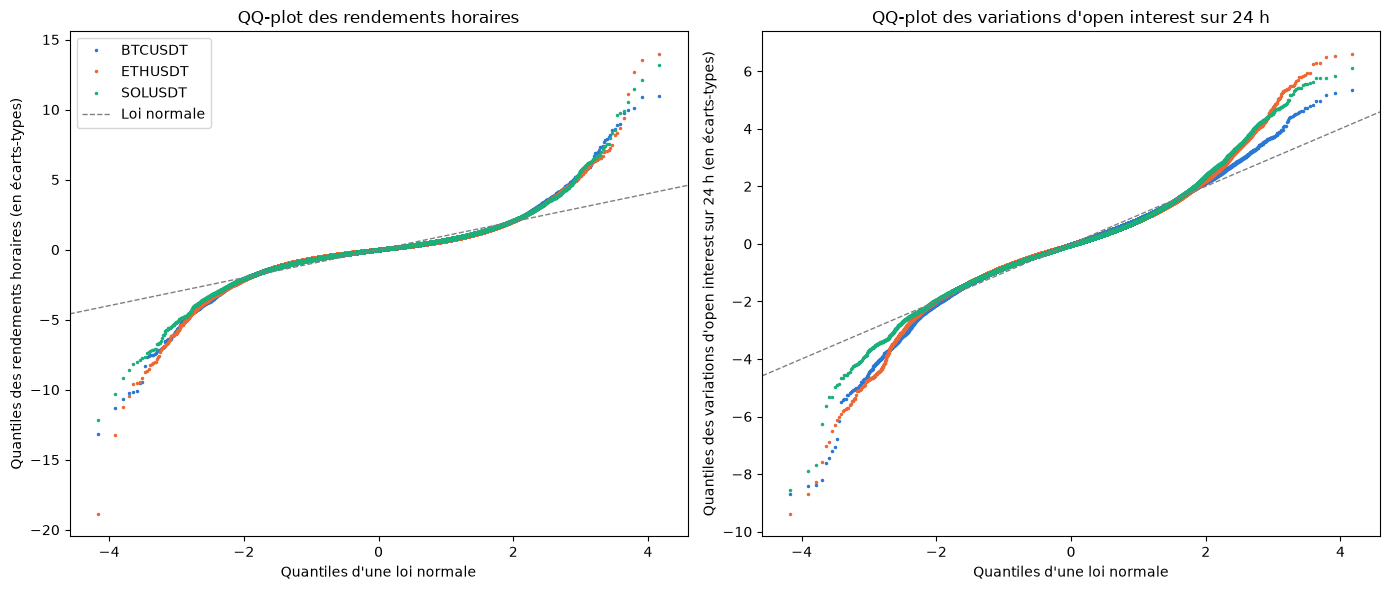

In [20]:
descriptif.graphique_qqplot(panel_cible, {"rendements horaires": descriptif.rendements_horaires,
                                          "variations d'open interest sur 24 h": descriptif.variation_oi_reduite})

Jusqu'à environ 2 σ, les variations d'open interest suivent à peu près une loi normale (5,3 à 5,7 % des heures sous −1,5 σ, contre 6,7 %) : sur le QQ-plot de droite, les points restent sur la droite entre −2 et +2. Les queues épaisses n'apparaissent qu'au-delà, surtout du côté des baisses (jusqu'à −9 σ, lors des krachs qui liquident des positions), et elles sont moins marquées que pour les prix, à gauche (kurtosis de 3 à 5, contre 11 à 18). Une baisse de 5 % est donc rare sans être extrême, mais elle n'a pas la même sévérité selon la crypto : elle touche 1,8 % des heures pour BTC et 3,4 % pour SOL, alors qu'une baisse de 1,5 σ en touche 1,8 % pour les trois.

**Nos choix** : à partir de l'étape 4, C2 exige une baisse de **1,5 σ**. Exprimée en écarts-types comme C1, la condition a la même sévérité pour chaque crypto, et 1,5 σ reste dans la zone où la loi normale décrit bien l'open interest : une baisse rare, sans être extrême. On garde 39 épisodes, presque autant qu'avec 5 % (43). La variante **δ = 1,2 σ** sert de contrôle : 51 épisodes, dont 16 en 2025-2026 au lieu de 10, au prix d'une condition moins spécifique.

### Deux exemples

BTC à gauche, SOL à droite : prix, open interest, funding et ratio long/short de tous les comptes, de 3 jours avant le début de l'épisode (tirets rouges) à 1 jour après le pic (tirets noirs).

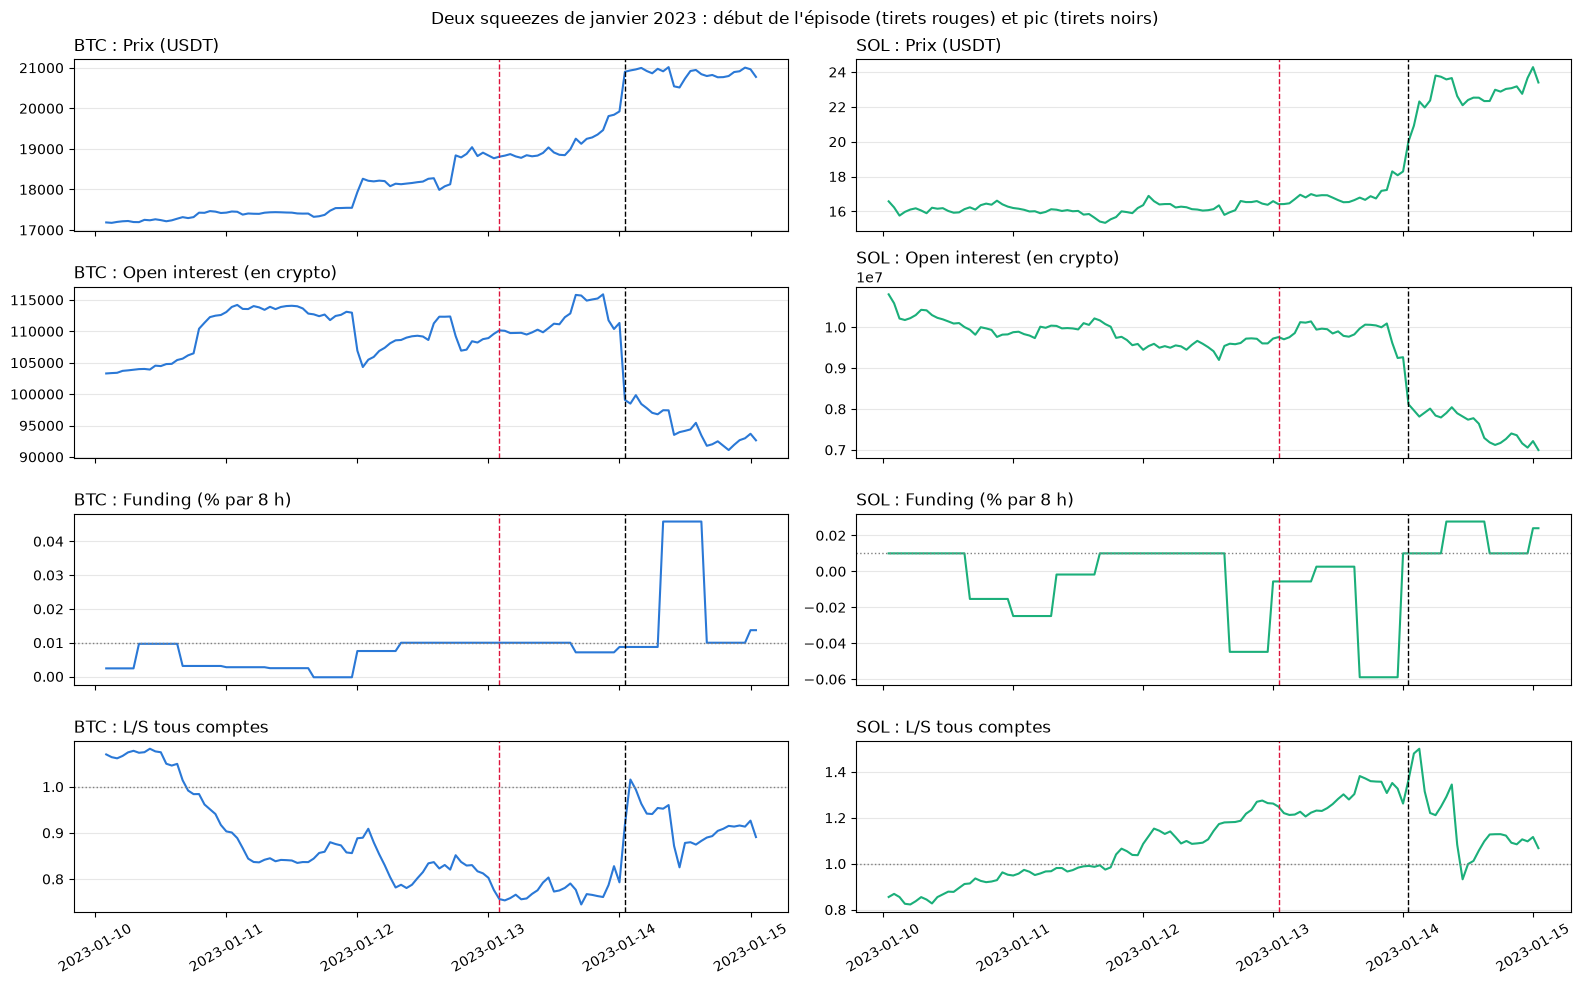

In [21]:
descriptif.graphique_exemples(panel_cible, [("BTCUSDT", "2023-01-13 02:00"), ("SOLUSDT", "2023-01-13 01:00")])

**BTC, 13-14 janvier 2023.** Le prix monte de 17 200 à 21 000 USDT en quatre jours. Avant le pic, le ratio long/short est bas (0,75 à 0,85) : une majorité de comptes est à découvert. Au pic, l'open interest chute d'un coup de 115 000 à 99 000 BTC et le ratio remonte au-dessus de 1 : les shorts ont été rachetés. Le funding, lui, reste proche du taux par défaut jusqu'au pic et ne signale rien.

**SOL, 13-14 janvier 2023.** Le prix passe de 16 à 23,7 USDT, et l'open interest baisse de près de 30 %. Ici, c'est le **funding** qui signale les shorts : il est négatif avant le pic (jusqu'à −0,06 % par 8 h), les shorts payaient donc pour garder leur position. Le ratio long/short est au contraire au-dessus de 1 : il compte les comptes, pas la taille des positions.

Les deux exemples vont dans le sens de H2 (des shorts nombreux puis rachetés), mais par des variables différentes. Aucune variable ne signale seule tous les squeezes : c'est ce que l'étape 4 examinera sur l'ensemble des épisodes.

### Bilan de l'étape 3

- La cible est **rare** (0,13 à 0,31 % des heures) et **concentrée en 2023** : 16 épisodes en tout, dont un seul en 2025-2026. Les comparaisons dans le temps reposent donc sur peu d'épisodes.
- **C2 isole le mécanisme** : plus de la moitié des fortes hausses viennent de nouveaux longs, et la baisse de l'open interest les écarte. C3 n'ajoute presque rien pour ces trois cryptos (voir l'étape 4 pour les autres).
- Les squeezes sont souvent **simultanés** sur plusieurs cryptos : ce sont des événements de marché.
- Le nombre de squeezes dépend surtout de **δ** : on passe à δ = 1,5 σ pour l'étape 4, avec δ = 1,2 σ comme contrôle.

## 4. Positionnement et squeezes

On cherche à savoir si le positionnement des traders à l’heure \(t\) donne une indication sur ce qui se passe dans les 24 heures suivantes. Si les shorts sont informés (H1), on s’attend à un rendement médian plus faible quand le positionnement est plus vendeur. Si les shorts sont fragiles (H2), on s’attend à des squeezes plus fréquents dans ces mêmes conditions.

L'étape 4 porte sur les **10 cryptos**, pour avoir plus d'épisodes et voir si les constats faits sur BTC, ETH et SOL se généralisent. La cible exige une baisse d'open interest de **δ = 1,5 σ** (voir l'étape 3) ; les autres seuils ne changent pas (k = 3, plancher 5 %, ratio taker > 1, horizon 24 h).

In [22]:
panel_complet = descriptif.charger_panel(avec_chauffe=True)
panel_cible_complet = ajouter_cible(panel_complet, delta_sigma=1.5)
panel_cible = descriptif.periode_etude(panel_cible_complet)
episodes_cible = descriptif.tableau_episodes(panel_cible)

frequence = descriptif.frequence_cible(panel_cible, episodes_cible)
display(frequence.xs("Total", level="année").round(3))
frequence["episodes"].unstack()

,heures,heures_positives,episodes,part_positive_pct
symbol,,,,
ADAUSDT,32832,65,9,0.198
BNBUSDT,32832,65,8,0.198
BTCUSDT,32832,191,12,0.582
DOGEUSDT,32832,11,6,0.034
DOTUSDT,32832,50,7,0.152
ETHUSDT,32832,159,14,0.484
LINKUSDT,32832,37,7,0.113
LTCUSDT,32832,30,4,0.091
SOLUSDT,32832,141,13,0.429


année,2023,2024,2025,2026,Total
symbol,,,,,
ADAUSDT,4,1,3,1,9
BNBUSDT,6,0,1,1,8
BTCUSDT,8,2,1,1,12
DOGEUSDT,1,1,2,2,6
DOTUSDT,2,0,1,4,7
ETHUSDT,8,2,3,1,14
LINKUSDT,2,1,1,3,7
LTCUSDT,1,0,1,2,4
SOLUSDT,8,1,1,3,13


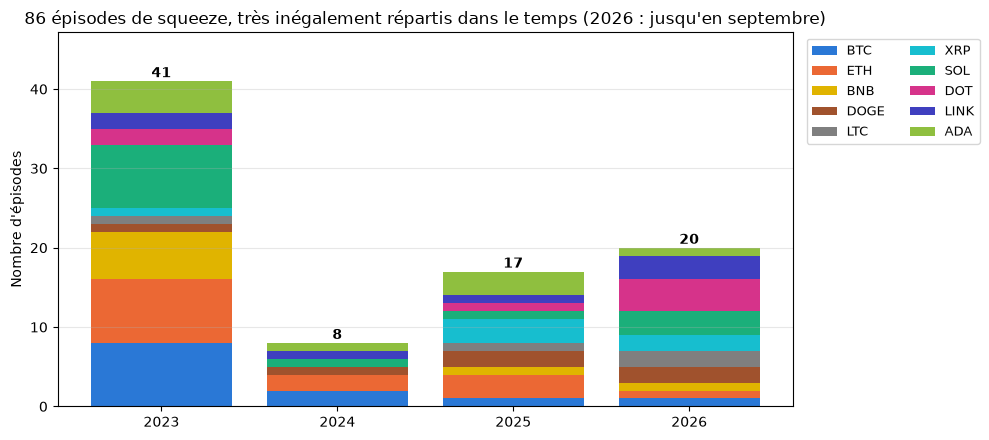

In [23]:
descriptif.graphique_episodes_par_annee(episodes_cible)

Avec δ = 1,5 σ, on compte **86 épisodes** sur les 10 cryptos : 41 en 2023, 8 en 2024, 17 en 2025 et 20 en 2026. Les nouvelles cryptos apportent surtout des épisodes récents (5 pour DOT et XRP en 2025-2026, 4 pour ADA et DOGE), si bien qu'une période de test sur 2025-2026 en contiendra 37.

La cible reste rare, et sa fréquence varie beaucoup : de 0,03 % des heures pour DOGE à 0,58 % pour BTC. Les épisodes des nouvelles cryptos sont plus courts (DOGE : 11 heures positives pour 6 épisodes ; BTC : 191 pour 12). Leurs squeezes sont donc encore plus rares.

Le graphique résume cette répartition : 41 épisodes en 2023, 8 seulement en 2024, puis 17 en 2025 et 20 en 2026 (jusqu'en septembre). La reprise de 2025-2026 vient surtout des nouvelles cryptos : BTC, ETH et SOL n'y comptent que 10 épisodes sur 37.

### Entonnoir avec la cible finale

On refait l'entonnoir de l'étape 3 avec la cible retenue (δ = 1,5 σ), en séparant BTC, ETH et SOL des sept autres cryptos. Le graphique donne la part des heures C1 qui passent chaque étape (nombre d'heures au-dessus des barres), le tableau le détail par crypto.

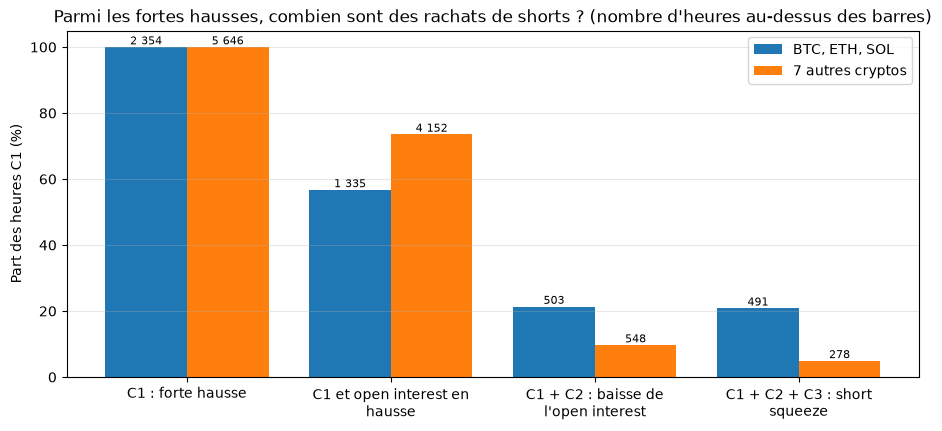

,C1 : forte hausse,C1 et open interest en hausse,C1 + C2 : baisse de l'open interest,C1 + C2 + C3 : short squeeze
symbol,,,,
ADAUSDT,761,495,98,65
BNBUSDT,827,632,98,65
BTCUSDT,810,437,191,191
DOGEUSDT,928,722,25,11
DOTUSDT,695,369,134,50
ETHUSDT,763,448,168,159
LINKUSDT,666,505,66,37
LTCUSDT,733,575,66,30
SOLUSDT,781,450,144,141


In [24]:
nombres_entonnoir = descriptif.entonnoir(panel_cible)
descriptif.graphique_entonnoir(descriptif.entonnoir_trois_grosses(nombres_entonnoir))
nombres_entonnoir

- **Chez les sept autres cryptos, les fortes hausses viennent surtout de nouveaux longs** : l'open interest monte pendant 74 % des heures C1, contre 57 % pour BTC, ETH et SOL.
- **C2 reste le principal filtre** : elle garde 21 % des heures C1 pour les trois grosses cryptos, 10 % pour les autres.
- **C3 ne compte que pour les petites cryptos** : elle n'écarte que 2 % des heures C1 + C2 de BTC, ETH et SOL (503 → 491), mais 49 % de celles des sept autres (548 → 278). Le tableau montre que l'effet est le plus fort pour DOT (134 → 50), XRP (61 → 20), DOGE (25 → 11) et LTC (66 → 30). Sur ces cryptos, une baisse d'open interest pendant une hausse ne s'accompagne pas toujours d'achats agressifs : C3 y joue bien son rôle de filtre, ce qu'on ne pouvait pas voir à l'étape 3.

In [25]:
evenements = descriptif.evenements_de_marche(episodes_cible)
display(evenements["cryptos"].value_counts().sort_index().rename_axis("Cryptos touchées").rename("Événements"))
evenements.sort_values("cryptos", ascending=False).head(5)

Cryptos touchées
1    16
2     8
3     1
4     2
5     4
6     2
9     1
Name: Événements, dtype: int64

,premier_pic,cryptos,liste
29,2026-02-06 16:00:00+00:00,9,"ADA, BNB, BTC, DOGE, DOT, LINK, LTC, SOL, XRP"
3,2023-01-14 01:00:00+00:00,6,"BNB, BTC, DOT, ETH, LINK, SOL"
33,2026-08-19 22:00:00+00:00,6,"DOGE, ETH, LINK, LTC, SOL, XRP"
14,2023-10-16 14:00:00+00:00,5,"BNB, BTC, ETH, LTC, SOL"
5,2023-03-13 01:00:00+00:00,5,"ADA, BNB, BTC, ETH, SOL"


Deux épisodes dont les pics sont à moins de 24 h d'écart, sur des cryptos différentes, forment un même **événement de marché**. Les 86 épisodes se regroupent en **34 événements** : 16 ne touchent qu'une crypto, les 18 autres en touchent plusieurs, jusqu'à 9 sur 10 le 6 février 2026.

La taille réelle de l'échantillon est donc plus proche de 34 que de 86. Les résultats qui suivent reposent sur quelques dizaines d'événements, et des épisodes simultanés ne sont pas des observations indépendantes.

### Contrôle des données avec Bybit

Les 7 nouvelles cryptos n'ont pas été décrites aux étapes 1 à 3. On vérifie donc les données Binance des 10 cryptos en les comparant à celles de Bybit, une plateforme indépendante : prix, open interest et funding doivent évoluer ensemble. Surtout, la cible repose sur une baisse d'open interest (C2) : si cette baisse se voit aussi sur Bybit, c'est un vrai rachat de positions et non une erreur de relevé de Binance.

In [26]:
fusion = descriptif.charger_fusion()
descriptif.comparer_bybit(fusion).round(3)

,Corrélation des rendements horaires,Corrélation des variations d'OI sur 24 h,Corrélation du funding,Écart de prix moyen (%),Heures sans OI Bybit (%)
BTCUSDT,1.000,0.541,0.778,0.013,0.003
ETHUSDT,1.000,0.502,0.784,0.013,0.003
BNBUSDT,0.999,0.483,0.878,0.057,0.003
DOGEUSDT,1.000,0.589,0.664,0.018,0.003
LTCUSDT,0.999,0.530,0.750,0.018,0.003
XRPUSDT,0.999,0.661,0.656,0.018,0.003
SOLUSDT,1.000,0.520,0.931,0.018,0.003
DOTUSDT,0.999,0.500,0.869,0.028,0.003
LINKUSDT,0.999,0.591,0.580,0.020,0.003
ADAUSDT,0.999,0.563,0.692,0.024,0.003


In [27]:
descriptif.episodes_sur_bybit(fusion, episodes_cible).round(1)

,episodes,variation_oi_binance_mediane_pct,variation_oi_bybit_mediane_pct,baisse_aussi_sur_bybit_pct
symbol,,,,
BTCUSDT,12,-7.1,-11.6,91.7
ETHUSDT,14,-7.0,-4.8,78.6
BNBUSDT,8,-8.5,-7.4,87.5
DOGEUSDT,6,-7.4,-2.5,83.3
LTCUSDT,4,-7.3,-4.9,100.0
XRPUSDT,6,-11.6,-6.7,83.3
SOLUSDT,13,-11.0,-12.5,84.6
DOTUSDT,7,-8.7,-7.5,100.0
LINKUSDT,7,-9.0,-7.8,85.7


- **Prix** : les rendements horaires des deux plateformes sont corrélés à 0,999 ou plus, et les prix ne diffèrent que de 0,01 à 0,06 % en moyenne. Les bougies Binance des 10 cryptos sont fiables.
- **Open interest et funding** : corrélés à 0,48-0,66 (variations sur 24 h) et à 0,58-0,93. Les deux plateformes n'ont pas les mêmes clients, on n'attend donc pas une égalité, mais les séries évoluent ensemble et aucune nouvelle crypto ne s'écarte des trois premières.
- **Épisodes** : selon la crypto, l'open interest Bybit baisse aussi entre t et le pic dans 79 à 100 % des épisodes. Les baisses retenues par C2 sont donc de vrais rachats de positions, pas des erreurs de relevé. Elles sont souvent plus faibles sur Bybit (médiane −2,5 % pour DOGE, −4,8 % pour ETH) : une partie des rachats a lieu sur Binance seulement.

### Comment se déroule un squeeze : étude d'événement

On aligne les 86 épisodes sur leur pic, puis on fait la moyenne de chaque variable heure par heure, de 72 h avant à 24 h après. Deux groupes servent de comparaison : les fortes hausses qui ne remplissent pas C2 (pas de rachat de positions), et 1 000 heures ordinaires tirées au hasard. Le prix, l'open interest et les ratios long/short sont exprimés en variation depuis 72 h avant le pic, pour pouvoir mélanger les cryptos.

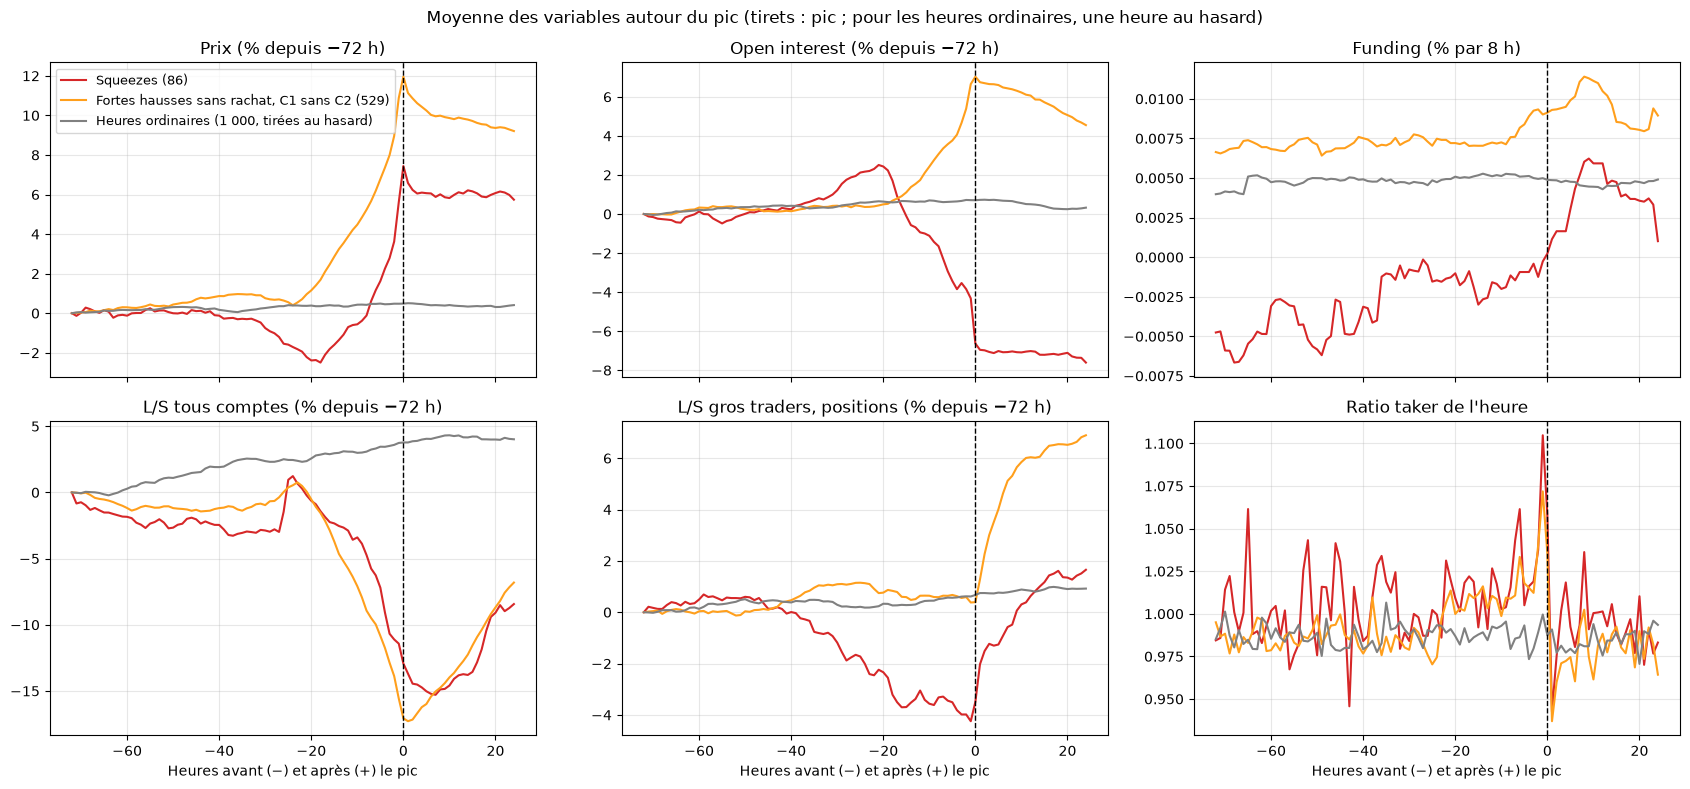

In [28]:
groupes = descriptif.groupes_etude_evenement(panel_cible, episodes_cible)
profils = descriptif.etude_evenement(panel_cible_complet, groupes)
descriptif.graphique_etude_evenement(profils)

- **Prix** : avant un squeeze, le prix baisse d'environ 2 % jusqu'à 20 h avant le pic, puis remonte de près de 10 % jusqu'au pic. Les fortes hausses sans rachat montent au contraire de façon régulière (+12 %).
- **Open interest** : c'est la différence la plus nette. Avant un squeeze, des positions s'ouvrent pendant la baisse (+2,5 % jusqu'à 20 h avant le pic), puis se ferment pendant la hausse (−7 % au pic). Pendant une hausse sans rachat, l'open interest monte avec le prix (+7 %) : ce sont de nouveaux longs.
- **Funding** : il est négatif pendant les 72 h qui précèdent un squeeze (autour de −0,005 % par 8 h), alors qu'il reste positif avant les autres hausses (+0,007 %) et en temps normal (+0,005 %). Les shorts paient pour garder leur position, puis le funding redevient positif au pic.
- **Ratio des gros traders en positions** : il baisse de 4 % pendant les 40 h qui précèdent le pic (les gros traders se placent à la baisse), puis remonte. Il ne bouge pas avant les autres hausses.
- **Ratio de tous les comptes** : il baisse pendant toutes les fortes hausses, avec ou sans rachat. Il réagit au prix plus qu'il ne l'annonce.
- **Ratio taker** : les achats agressifs culminent à l'heure du pic, ce que vérifie C3.

C'est le scénario de H2 : des shorts s'accumulent pendant une baisse, en payant le funding, puis une hausse les force à racheter. Surtout, le funding, l'open interest et le ratio des gros traders s'écartent de la normale **un à trois jours avant le pic**, donc avant l'heure t de la prévision (17 à 24 h avant le pic en médiane) : une prévision à 24 h est envisageable.

### Taux de squeeze par décile

Pour chaque crypto, on classe les heures en déciles d'une variable de positionnement, puis on calcule la part des heures suivies d'un squeeze. Les déciles sont calculés crypto par crypto.

On regarde d'abord les 5 variables ensemble, toutes cryptos réunies, puis le détail par crypto pour le ratio des gros traders et le funding.

In [29]:
variables = descriptif.variables_etape_4(panel_cible_complet)
VARIABLES_CARTES = {nom: descriptif.NOMS_ETAPE_4[nom]
                    for nom in ["funding_8h", "ls_global", "ls_top_positions", "variation_oi_24h", "variation_oi_7j"]}
descriptif.taux_par_decile_toutes_variables(variables, VARIABLES_CARTES).round(1)

decile,1,2,3,4,5,6,7,8,9,10
Funding (% par 8 h),0.6,0.2,0.3,0.2,0.1,0.1,0.4,0.1,0.0,0.2
L/S tous comptes,0.7,0.5,0.2,0.2,0.2,0.1,0.1,0.1,0.1,0.2
"L/S gros traders, positions",0.8,0.6,0.3,0.3,0.2,0.1,0.1,0.1,0.0,0.0
Variation OI 24 h (%),0.1,0.1,0.2,0.2,0.2,0.2,0.2,0.3,0.3,0.5
Variation OI 7 jours (%),0.3,0.2,0.1,0.1,0.1,0.2,0.2,0.3,0.4,0.5


In [30]:
descriptif.tableau_taux_par_decile(descriptif.taux_squeeze_par_decile(variables, "ls_top_positions")).round(1)

decile,1,2,3,4,5,6,7,8,9,10
symbol,,,,,,,,,,
BTCUSDT,0.5,2.0,1.4,0.8,0.7,0.1,0.0,0.2,0.0,0.0
ETHUSDT,1.6,1.4,0.9,0.3,0.3,0.2,0.0,0.0,0.1,0.0
BNBUSDT,0.7,0.8,0.2,0.0,0.2,0.0,0.0,0.0,0.0,0.0
DOGEUSDT,0.1,0.0,0.1,0.1,0.0,0.0,0.0,0.0,0.0,0.0
LTCUSDT,0.5,0.0,0.0,0.1,0.4,0.0,0.0,0.0,0.0,0.0
XRPUSDT,0.0,0.2,0.1,0.1,0.0,0.0,0.1,0.2,0.0,0.0
SOLUSDT,3.1,0.0,0.0,0.5,0.3,0.2,0.2,0.1,0.0,0.0
DOTUSDT,0.0,0.9,0.0,0.5,0.0,0.0,0.0,0.1,0.0,0.1
LINKUSDT,0.1,0.1,0.2,0.4,0.2,0.0,0.0,0.2,0.1,0.0


In [31]:
descriptif.tableau_taux_par_decile(descriptif.taux_squeeze_par_decile(variables, "funding_8h")).round(1)

decile,1,2,3,4,5,6,7,8,9,10
symbol,,,,,,,,,,
BTCUSDT,0.7,0.7,0.8,0.1,0.1,0.5,0.5,NaN,NaN,1.6
ETHUSDT,1.1,0.3,1.0,0.2,0.3,0.0,0.6,NaN,NaN,0.2
BNBUSDT,0.2,0.3,NaN,NaN,NaN,NaN,NaN,0.1,0.0,0.1
DOGEUSDT,0.2,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0
LTCUSDT,0.3,0.0,0.3,0.2,0.0,0.0,NaN,NaN,NaN,0.0
XRPUSDT,0.1,0.2,0.0,0.0,0.3,0.0,NaN,NaN,NaN,0.0
SOLUSDT,2.1,0.2,0.1,0.4,0.5,0.2,0.3,NaN,NaN,0.0
DOTUSDT,0.5,0.1,0.0,0.3,0.1,0.2,NaN,NaN,NaN,0.0
LINKUSDT,0.2,0.2,0.2,0.2,0.1,NaN,NaN,NaN,NaN,0.0


- **Vue d'ensemble** (premier tableau) : trois variables donnent un gradient net. Le taux de squeeze est le plus élevé quand le ratio des gros traders en positions est bas (0,8 % au premier décile, 0,6 % au deuxième, 0,1 % ou moins à partir du sixième), quand le ratio de tous les comptes est bas (0,7 et 0,5 % dans les deux premiers déciles, 0,1 à 0,2 % ailleurs), et quand l'open interest a le plus augmenté sur 24 h (de 0,1 % au premier décile à 0,5 % au dernier). Sur 7 jours, l'effet de l'open interest se concentre dans les deux derniers déciles (0,4 et 0,5 %). Le funding n'a de signal net qu'au premier décile (0,6 %).
- **Ratio des gros traders, crypto par crypto** (deuxième tableau) : le gradient se retrouve pour 7 cryptos sur 10 (BTC, ETH, BNB, LTC, SOL, DOT et ADA ont leurs squeezes dans les premiers déciles). DOGE, XRP et LINK n'en montrent pas.
- **Funding, crypto par crypto** (troisième tableau) : le premier décile (funding le plus bas) est tiré par SOL (2,1 %), ETH (1,1 %), ADA (0,7 %) et DOT (0,5 %). BTC reste l'exception (1,6 % au dernier décile). Les cases vides (NaN) sont des déciles vides : beaucoup d'heures sont exactement au taux par défaut et ne se répartissent pas en déciles. Le funding se lit donc mieux comme un écart à ce taux que comme un niveau.
- **Open interest** : les squeezes suivent souvent une accumulation de positions, ce qui va dans le sens de H2 : plus il y a de positions ouvertes, plus il y en a à racheter.

Sur les 10 cryptos, les liens vont dans le sens de H2, mais ils sont portés par quelques cryptos, surtout les trois plus grosses. Les déciles portent encore sur des niveaux bruts, qui dérivent dans le temps (étape 2) : l'exercice sera refait avec les z-scores glissants.

### Compter en épisodes plutôt qu'en heures

Dans les tableaux ci-dessus, un squeeze long compte plus d'heures positives qu'un squeeze court : les cryptos aux squeezes longs (BTC, ETH, SOL) pèsent donc plus lourd. Ici, chaque épisode compte une fois : on regarde dans quel décile tombe sa première heure positive, et on compare à la part des heures du décile (tirets). Sans lien, les barres seraient au niveau des tirets. Les variables de prix (rendement passé, volatilité, écart au plus haut récent) sont ajoutées pour voir si le prix annonce les squeezes aussi bien que le positionnement.

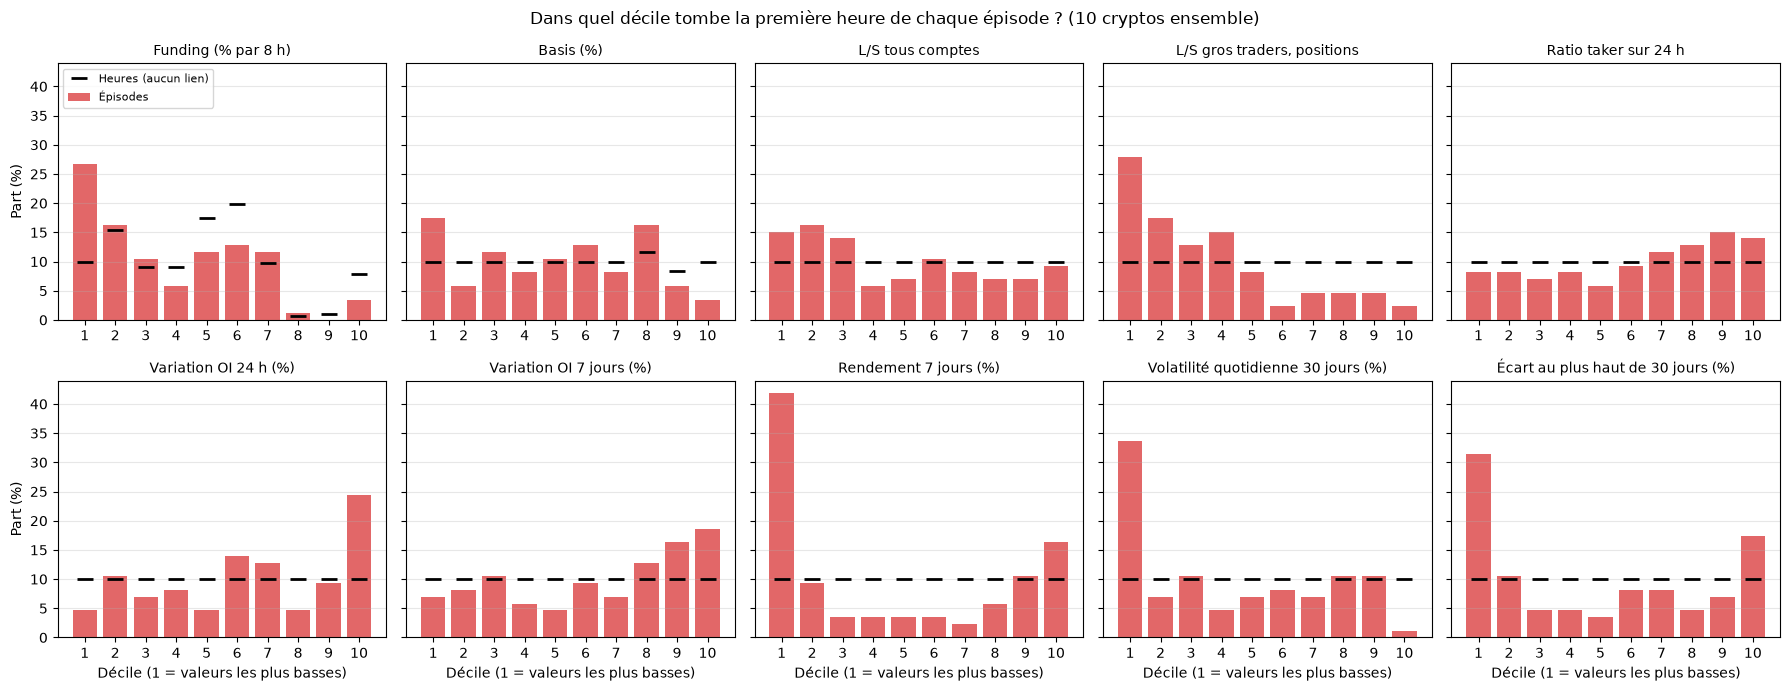

In [32]:
parts = descriptif.part_episodes_par_decile(variables, episodes_cible, {**descriptif.NOMS_ETAPE_4, **descriptif.NOMS_PRIX})
descriptif.graphique_part_episodes(parts)

- **Le ratio des gros traders en positions** reste le signal le plus net : 28 % des épisodes commencent dans son premier décile, 45 % dans les deux premiers, contre 20 % attendus.
- **Le funding** : 27 % des épisodes commencent dans le premier décile, contre 10 % des heures.
- **L'open interest** : 24 % des épisodes commencent après les plus fortes hausses sur 24 h, 35 % dans les deux derniers déciles sur 7 jours.
- **Le ratio taker sur 24 h** monte un peu dans les derniers déciles (13 à 15 %) ; **la basis** ne montre pas de tendance nette.
- **Le ratio de tous les comptes** est plus faible compté en épisodes (15 % au premier décile) : son signal en heures venait surtout des longs squeezes de BTC, ETH et SOL.
- **Les variables de prix sont les plus fortes** : 42 % des épisodes commencent après les pires rendements sur 7 jours, 31 % loin du plus haut de 30 jours. Les squeezes sont souvent des rebonds après une chute, comme le montrait l'étude d'événement. Une partie de ce que montre le positionnement est donc déjà dans le prix.
- **La volatilité** : 34 % des épisodes commencent dans le décile le plus calme. C'est en partie mécanique : C1 exige une hausse de 3 σ, plus facile à atteindre quand σ est bas, tant que le plancher de 5 % ne joue pas.

### Rendement à 24 h par décile de ratio long/short

Rendement du perpétuel entre la clôture de t et celle de t + 24 h. La médiane teste H1 (une baisse quand les shorts sont nombreux), le quantile 95 % teste H2 (les fortes hausses), et le quantile 5 % montre les fortes baisses.

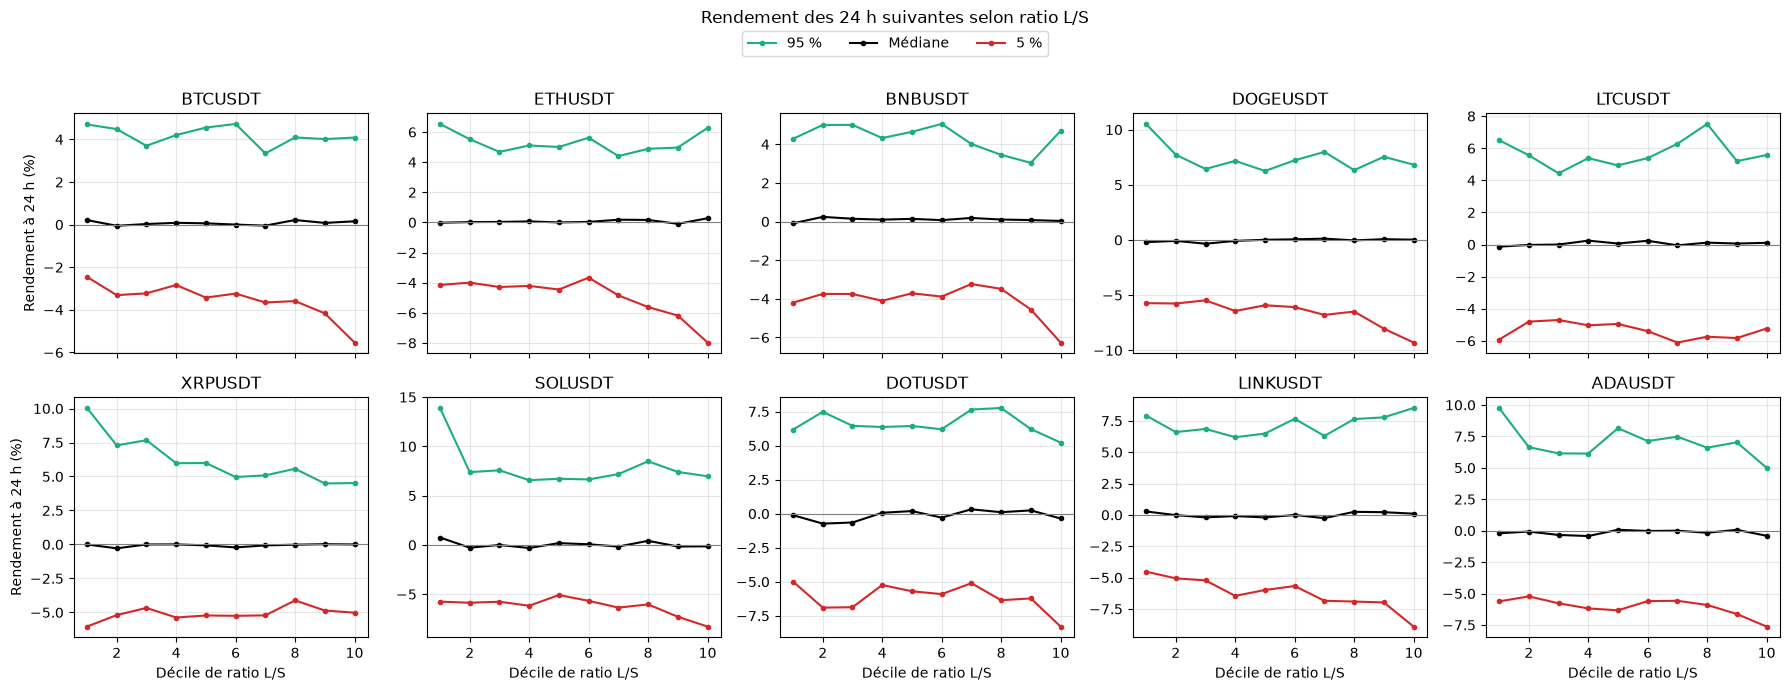

In [33]:
tableau_rendements = descriptif.rendement_par_decile(panel_cible, "ls_global")
descriptif.graphique_rendement_par_decile(tableau_rendements, "ratio L/S")

- **Médiane** : elle reste proche de 0 dans tous les déciles et pour toutes les cryptos (entre −0,7 et +0,8 %). Quand les shorts sont nombreux, le prix ne baisse pas plus que d'habitude : H1 n'est pas soutenue.
- **Quantile 95 %** : il est le plus haut au premier décile pour SOL (13,9 %), DOGE (10,5 %), XRP (10,0 %), ADA (9,7 %) et ETH (6,5 %). Les fortes hausses sont plus fréquentes quand les shorts sont nombreux, y compris pour DOGE et XRP, qui comptent pourtant peu d'épisodes : leurs hausses ne s'accompagnent pas toujours d'une baisse d'open interest suffisante pour passer C2.
- **Quantile 5 %** : il est le plus bas au dernier décile pour 8 cryptos sur 10. Quand presque tous les comptes sont longs, les chutes sont plus fortes : c'est le phénomène symétrique, qui renforce l'idée de positions fragiles.

### Croisement du funding et de l'open interest

Les deux signaux de H2 réunis (des shorts qui paient le funding, et des positions qui s'accumulent) annoncent-ils plus de squeezes que chacun séparément ?

In [34]:
descriptif.croisement_funding_oi(variables).round(3)

heures                        \
                       OI en baisse sur 24 h OI en hausse sur 24 h   
Funding négatif                        35169                 30436   
Funding positif ou nul                132366                130169   

                                    taux_pct                        
                       OI en baisse sur 24 h OI en hausse sur 24 h  
Funding négatif                        0.313                 0.486  
Funding positif ou nul                 0.126                 0.264

Les deux signaux s'additionnent : le taux de squeeze passe de 0,13 % (funding positif, open interest en baisse) à **0,49 %** quand ils sont réunis, presque quatre fois plus. Chacun compte séparément : à sens de l'open interest donné, un funding négatif multiplie le taux par 1,8 à 2,5 ; à signe du funding donné, une hausse de l'open interest le multiplie par 1,6 à 2,1. Le funding n'est négatif que 20 % des heures.

### Positionnement et variables de prix

Une partie du positionnement reflète-t-elle simplement le prix ? Corrélation de Spearman entre chaque variable de positionnement et chaque variable de prix, en moyenne sur les 10 cryptos.

In [35]:
descriptif.correlations_prix_positionnement(variables).round(2)

,Rendement 7 jours (%),Volatilité quotidienne 30 jours (%),Écart au plus haut de 30 jours (%)
Funding (% par 8 h),0.31,0.01,0.35
Basis (%),0.26,0.03,0.29
L/S tous comptes,-0.36,0.08,-0.36
"L/S gros traders, positions",0.08,0.21,0.05
Ratio taker sur 24 h,0.16,-0.03,0.09
Variation OI 24 h (%),0.08,-0.04,0.08
Variation OI 7 jours (%),0.29,-0.07,0.19


- **Le ratio de tous les comptes et le funding suivent le prix** (−0,36 et +0,31 avec le rendement sur 7 jours) : après une baisse, les comptes sont plus souvent longs et le funding plus bas. Une partie de leur signal est déjà dans le prix.
- **Le ratio des gros traders en positions** n'est presque pas lié au rendement passé (0,08) ni à l'écart au plus haut (0,05), un peu à la volatilité (0,21). C'est la variable la plus susceptible d'apporter une information que le prix n'a pas.
- **La variation d'open interest** sur 7 jours suit en partie le prix (0,29), celle sur 24 h presque pas (0,08).

### Contrôle : cible avec δ = 1,2 σ

Avec une cible moins stricte, qui compte plus d'épisodes en 2025-2026, les liens entre le positionnement et les squeezes tiennent-ils ? Même tableau que le premier de la partie « Taux de squeeze par décile », avec δ = 1,2 σ.

In [36]:
variables_12 = descriptif.variables_etape_4(ajouter_cible(panel_complet, delta_sigma=1.2))
descriptif.taux_par_decile_toutes_variables(variables_12, VARIABLES_CARTES).round(1)

decile,1,2,3,4,5,6,7,8,9,10
Funding (% par 8 h),0.7,0.3,0.3,0.2,0.1,0.1,0.5,0.1,0.0,0.2
L/S tous comptes,0.7,0.7,0.2,0.2,0.2,0.2,0.1,0.1,0.1,0.2
"L/S gros traders, positions",0.9,0.6,0.3,0.3,0.2,0.1,0.1,0.1,0.0,0.0
Variation OI 24 h (%),0.2,0.2,0.2,0.2,0.3,0.3,0.3,0.3,0.4,0.6
Variation OI 7 jours (%),0.3,0.2,0.2,0.1,0.2,0.2,0.2,0.3,0.5,0.6


Avec δ = 1,2 σ, le tableau est presque identique à celui obtenu avec δ = 1,5 σ : les mêmes variables donnent les mêmes gradients, un peu plus marqués (ratio des gros traders : 0,9 % au premier décile ; variation d'open interest sur 24 h : 0,6 % au dernier). Les liens entre le positionnement et les squeezes ne dépendent donc pas du seuil exact de C2.

### Bilan de l'étape 4

- **H1 n'est pas soutenue** : le rendement médian ne baisse pas quand les shorts sont nombreux.
- **H2 est soutenue** par plusieurs signaux qui précèdent le pic d'un à trois jours : funding négatif, open interest en hausse, gros traders placés à la baisse. Réunis, un funding négatif et un open interest en hausse multiplient le taux de squeeze par presque quatre.
- **Le ratio des gros traders en positions** donne le signal le plus net et le moins lié au prix : c'est la variable clé de l'étape 5.
- **Le prix compte beaucoup** : les squeezes suivent souvent une chute. Une partie du signal du positionnement est déjà dans le prix ; seul le ratio des gros traders en positions en est presque indépendant.
- **Prudence** : 86 épisodes mais 34 événements de marché distincts ; des niveaux bruts qui dérivent dans le temps (à refaire avec les z-scores glissants) ; un lien en partie mécanique avec la volatilité.
- **Période** : ces constats portent sur toute la période 2023-2026, et ont servi à choisir δ = 1,5 σ et à désigner le ratio des gros traders comme variable clé. L'étape 5 vérifie qu'ils tiennent aussi sur 2023-2024 seule et sur 2025-2026 seule.

## 5. Hétérogénéité et robustesse

L'étape 4 a retenu trois signaux de H2 : des **gros traders placés à la baisse**, un **funding négatif** et une **forte hausse de l'open interest**. On vérifie ici qu'ils tiennent partout, sous trois angles :
1. **par crypto et dans le temps** : pour les petites cryptos comme pour les grosses, en 2023-2024 comme en 2025-2026 ;
2. **selon le sentiment du marché** (indice Fear & Greed) ;
3. **sur une autre plateforme** : retrouve-t-on le même mécanisme sur Bybit ?

On garde la cible de l'étape 4 (10 cryptos, δ = 1,5 σ). Le contrôle avec δ = 1,2 σ a déjà été fait à la fin de l'étape 4.

### Par crypto et dans le temps

Chaque signal est vrai ou faux à chaque heure :
- **gros traders placés à la baisse** : ratio long/short des gros traders en positions dans ses déciles 1 et 2 ;
- **funding négatif** : funding < 0 ;
- **forte hausse de l'open interest** : variation sur 24 h dans ses déciles 9 et 10.

Les déciles sont calculés crypto par crypto sur 2023-2026, comme à l'étape 4. Pour chaque groupe d'heures, on divise le taux de squeeze quand le signal est présent par le taux quand il est absent : un rapport de 3 veut dire trois fois plus de squeezes, un rapport de 1 aucun effet.

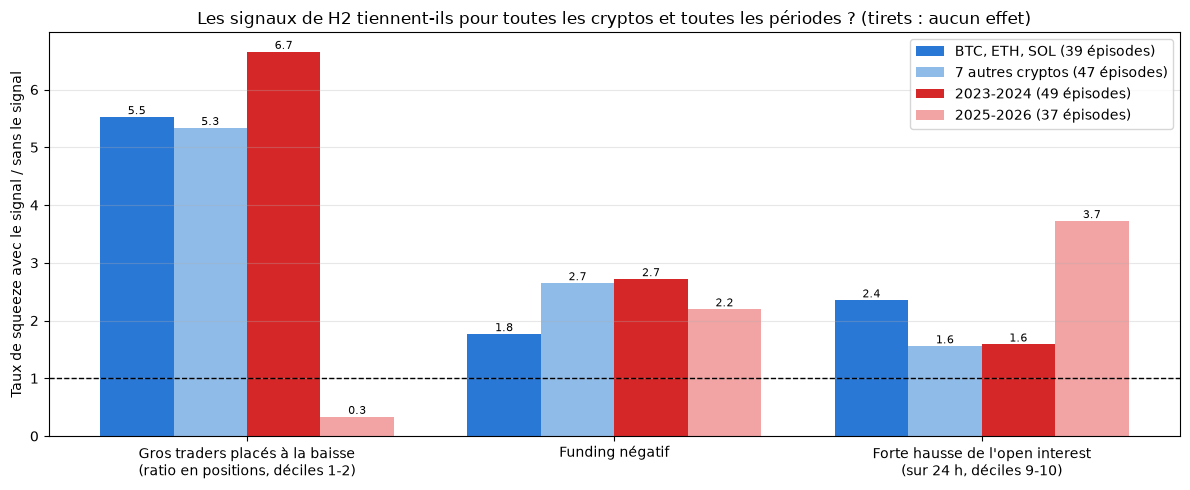

In [37]:
effets = descriptif.effet_des_signaux(variables, episodes_cible)
descriptif.graphique_effet_des_signaux(effets)

- **Le funding négatif et la hausse de l'open interest marchent partout** : le rapport va de 1,8 à 2,7 pour le funding et de 1,6 à 3,7 pour l'open interest, dans les quatre groupes. Ce sont des signaux robustes.
- **Le signal des gros traders est le plus fort**, avec des rapports de 5,3 à 6,7, pour les grosses comme pour les petites cryptos et en 2023-2024. **Mais il s'inverse en 2025-2026** (0,3) : quand les gros traders sont placés à la baisse, il y a moins de squeezes que d'habitude.

Cette inversion vient-elle d'un changement de comportement, ou d'un changement de niveau du ratio ? On compare les déciles calculés sur 2023-2026 à des déciles recalculés dans chaque période :

In [38]:
descriptif.effet_selon_deciles(variables, episodes_cible).round(2)

Heures avec le signal, déciles de 2023-2026 (%)  \
groupe    signal                                                                                                
2023-2024 Gros traders placés à la baisse (ratio en posit...                                            30.68   
          Funding négatif                                                                               13.56   
          Forte hausse de l'open interest (sur 24 h, déci...                                            21.31   
2025-2026 Gros traders placés à la baisse (ratio en posit...                                             7.79   
          Funding négatif                                                                               27.35   
          Forte hausse de l'open interest (sur 24 h, déci...                                            18.51   

                                                              Rapport, déciles de 2023-2026  \
groupe    signal                                                                              
2023-2024 Gros traders placés à la baisse (ratio en posit...                           6.66   
          Funding négatif                                                              2.72   
          Forte hausse de l'open interest (sur 24 h, déci...                           1.59   
2025-2026 Gros traders placés à la baisse (ratio en posit...                           0.34   
          Funding négatif                                                              2.20   
          Forte hausse de l'open interest (sur 24 h, déci...                           3.73   

                                                              Rapport, déciles de la période  
groupe    signal                                                                              
2023-2024 Gros traders placés à la baisse (ratio en posit...                            4.43  
          Funding négatif                                                               2.72  
          Forte hausse de l'open interest (sur 24 h, déci...                            1.57  
2025-2026 Gros traders placés à la baisse (ratio en posit...                            3.02  
          Funding négatif                                                               2.20  
          Forte hausse de l'open interest (sur 24 h, déci...                            3.78

- **C'est un effet de niveau** : avec les déciles de 2023-2026, 31 % des heures de 2023-2024 sont dans les déciles 1-2 du ratio des gros traders, contre 8 % seulement en 2025-2026. Le ratio a monté (étape 2), et les seuils fixés sur toute la période ne sont presque plus atteints en 2025-2026.
- **Mesuré dans chaque période, le signal tient** : rapport de 4,4 en 2023-2024 et de 3,0 en 2025-2026. Les deux autres signaux changent peu.
- **Conséquences pour la suite** :
  - c'est la preuve qu'il faut des **variables relatives** (z-scores glissants) et non des niveaux bruts. Avec des niveaux bruts, un modèle entraîné sur 2023-2024 et testé sur 2025-2026 se serait trompé de sens ;
  - les trois signaux marchent **sur 2023-2024 seule comme sur 2025-2026 seule** : ils ne dépendent pas d'une période particulière (voir la limite du bilan de l'étape 4).

### Selon le sentiment du marché : Fear & Greed

L'indice Fear & Greed (alternative.me) résume chaque jour le sentiment du marché crypto, de 0 (peur extrême) à 100 (avidité extrême). Il est commun à toutes les cryptos, et chaque heure reçoit la valeur de la veille. On classe les heures selon les cinq classes officielles de l'indice, puis on compare la part des épisodes (à leur première heure) à la part des heures dans chaque classe.

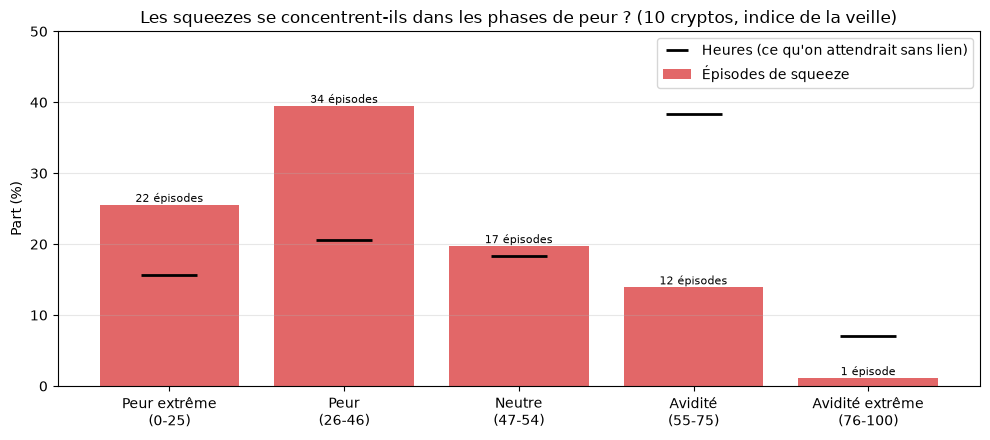

,heures_pct,episodes,taux_squeeze_pct,episodes_pct
fng,,,,
Peur extrême\n(0-25),15.71,22,0.30,25.58
Peur\n(26-46),20.61,34,0.57,39.53
Neutre\n(47-54),18.27,17,0.28,19.77
Avidité\n(55-75),38.31,12,0.04,13.95
Avidité extrême\n(76-100),7.09,1,0.07,1.16


In [39]:
tableau_fng = descriptif.squeezes_par_classe_fng(variables, episodes_cible)
descriptif.graphique_fng(tableau_fng)
tableau_fng.round(2)

- **Les squeezes se concentrent dans les phases de peur** : la peur et la peur extrême couvrent 36 % des heures mais 65 % des épisodes (56 sur 86). À l'inverse, l'avidité et l'avidité extrême couvrent 45 % des heures mais 15 % des épisodes (13).
- Le taux de squeeze est de **0,57 % des heures dans la classe « peur »** (0,30 % en peur extrême), **contre 0,04 % dans la classe « avidité »**, quatorze fois moins.
- C'est cohérent avec H2 : les shorts s'accumulent quand le marché a peur, et c'est alors qu'un rebond peut les forcer à racheter.

Le Fear & Greed apporte-t-il une information nouvelle, ou résume-t-il ce qu'on mesure déjà ? Corrélation de Spearman avec les autres variables, en moyenne sur les cryptos :

In [40]:
descriptif.correlations_fng(variables).round(2)

Rendement 7 jours (%)                  0.28
Volatilité quotidienne 30 jours (%)    0.14
Écart au plus haut de 30 jours (%)     0.35
Funding (% par 8 h)                    0.50
Basis (%)                              0.43
L/S tous comptes                       0.14
L/S gros traders, positions            0.33
Ratio taker sur 24 h                  -0.18
Variation OI 24 h (%)                 -0.01
Variation OI 7 jours (%)               0.02
Name: Corrélation avec le Fear & Greed, dtype: float64

- **L'indice suit surtout le funding** (0,50), la basis (0,43), l'écart au plus haut de 30 jours (0,35) et le rendement sur 7 jours (0,28) : la peur arrive après une baisse, quand le funding est bas.
- Il est aussi lié au ratio des gros traders (0,33), mais pas à la variation de l'open interest.

Le Fear & Greed est donc en grande partie un résumé du prix et du funding. Il pourra servir de variable de contexte, mais on ne s'attend pas à ce qu'il apporte beaucoup en plus du funding et des variables de prix.

### Sur une autre plateforme : Binance contre Bybit

Bybit ne donne pas le volume des acheteurs agressifs : C3 n'y est pas calculable. Pour comparer à armes égales, on définit ici les squeezes par **C1 + C2 sur les deux plateformes**, chacune avec ses propres prix et son propre open interest (δ = 1,5 σ). Deux épisodes se correspondent si leurs pics sont à moins de 24 h d'écart.

In [41]:
fusion_complet = descriptif.charger_fusion(avec_chauffe=True)
cible_bybit_complet = descriptif.cible_bybit(fusion_complet)
cible_binance_c12 = descriptif.sans_c3(panel_cible_complet)
episodes_binance_c12 = descriptif.tableau_episodes(descriptif.periode_etude(cible_binance_c12))
episodes_bybit = descriptif.tableau_episodes(descriptif.periode_etude(cible_bybit_complet))
descriptif.accord_binance_bybit(episodes_binance_c12, episodes_bybit).round(1)

,episodes_binance,episodes_bybit,binance_retrouves_sur_bybit_pct,bybit_retrouves_sur_binance_pct
symbol,,,,
BTCUSDT,12.0,18.0,75.0,50.0
ETHUSDT,16.0,17.0,62.5,58.8
BNBUSDT,10.0,8.0,60.0,75.0
DOGEUSDT,9.0,8.0,33.3,37.5
LTCUSDT,8.0,12.0,75.0,50.0
XRPUSDT,11.0,13.0,72.7,61.5
SOLUSDT,16.0,12.0,62.5,83.3
DOTUSDT,16.0,13.0,56.2,69.2
LINKUSDT,11.0,9.0,63.6,77.8


- Les deux plateformes comptent **autant d'épisodes** (122 sur Binance, 126 sur Bybit).
- **Environ 6 sur 10 se retrouvent sur l'autre plateforme** : 63 % des épisodes Binance ont un épisode Bybit à moins de 24 h, et 61 % dans l'autre sens. L'accord est le plus faible pour DOGE (33 à 38 %).
- L'accord n'est pas parfait parce que les conditions sont des seuils : une baisse d'open interest de 1,4 σ sur une plateforme et de 1,6 σ sur l'autre suffit à faire passer C2 d'un seul côté.

Le mécanisme, lui, est-il le même ? Étude d'événement refaite sur chaque plateforme avec ses propres données :

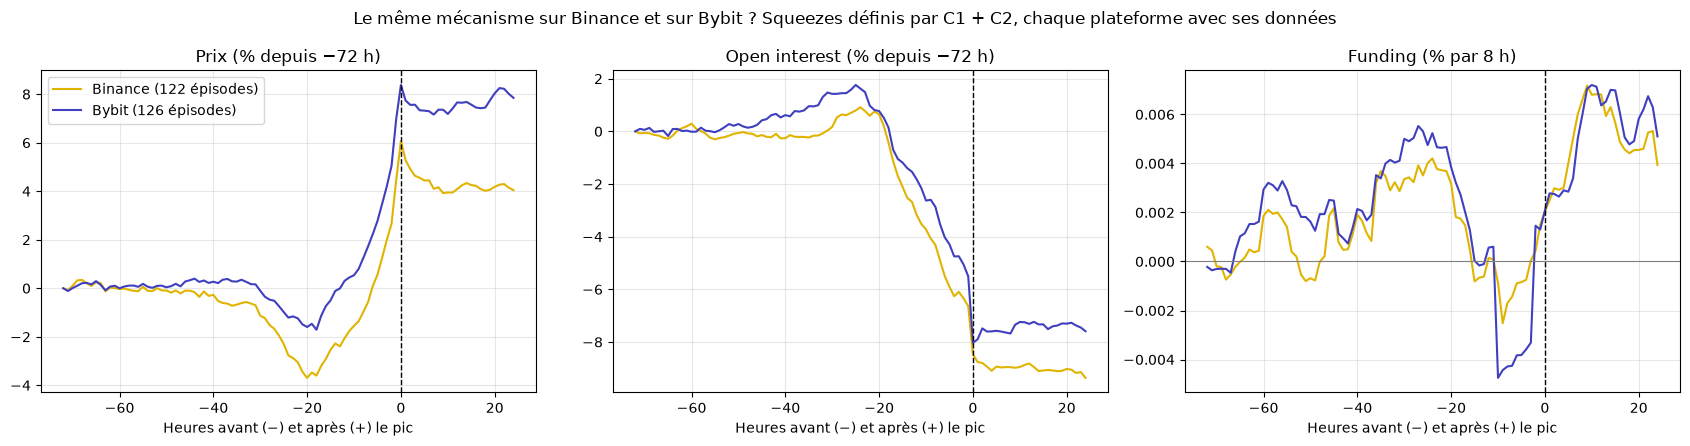

In [42]:
descriptif.graphique_binance_bybit(cible_binance_c12, episodes_binance_c12, cible_bybit_complet, episodes_bybit)

- **Les profils sont presque superposés** : le prix baisse jusqu'à environ 20 h avant le pic, puis monte jusqu'à +6 à +8 % au pic (par rapport à 72 h avant) ; l'open interest monte légèrement, puis chute d'environ 8 % entre 20 h avant le pic et le pic ; le funding suit la même trajectoire sur les deux plateformes.
- Le mécanisme du squeeze n'est donc **pas propre aux clients de Binance** : la baisse d'open interest pendant la hausse est un vrai rachat de positions, visible sur un autre marché.
- Ici, le funding n'est négatif que dans les dix heures qui précèdent le pic, alors qu'il l'était pendant trois jours à l'étape 4. Sans C3, la cible compte 36 épisodes de plus, surtout sur les petites cryptos (voir l'entonnoir de l'étape 4) : ce sont vraisemblablement des épisodes au funding positif, qui diluent le signal. Le funding est donc un signal plus net quand les achats agressifs confirment le squeeze.

### Bilan de l'étape 5

- **Le funding négatif et la hausse de l'open interest** annoncent des squeezes plus fréquents pour les grosses et les petites cryptos, en 2023-2024 comme en 2025-2026.
- **Le ratio des gros traders** est le signal le plus fort partout, **à condition d'être mesuré par rapport à son niveau récent** : en niveau brut, il s'inverse en 2025-2026. Il faut le mesurer en relatif (z-score glissant), pas en niveau.
- **Les squeezes se concentrent dans les phases de peur** (65 % des épisodes pour 36 % des heures), mais l'indice Fear & Greed résume surtout le funding et le prix.
- **Sur Bybit, le mécanisme est le même**, et 6 épisodes sur 10 s'y retrouvent.
- **Limites** : peu d'épisodes par groupe (37 à 49), et C3 absente de la comparaison avec Bybit.

### Bilan de l'analyse descriptive

- **La cible est rare** (0,03 à 0,58 % des heures selon la crypto) : un modèle de prévision devrait être jugé par la PR-AUC face à cette base naïve, jamais par l'accuracy.
- **H1 n'est pas soutenue** : quand les shorts sont nombreux, le rendement médian à 24 h ne baisse pas.
- **H2 est soutenue** : avant un squeeze, des shorts s'accumulent pendant une baisse, en payant le funding, puis sont rachetés pendant la hausse. Les signaux apparaissent un à trois jours avant le pic, ils tiennent pour toutes les cryptos et toutes les périodes, et le mécanisme se retrouve sur Bybit.
- **Prolongement possible** : un modèle de prévision, non demandé pour l'ENSAE et non réalisé ici. Il utiliserait des variables relatives à chaque crypto (z-scores glissants, écart du funding au taux par défaut), serait validé par date avec toutes les cryptos ensemble, en refaisant les choix de seuils sur sa seule période d'entraînement, et devrait battre un modèle « prix seuls », car les squeezes suivent souvent une chute du prix.